# 01_network — 자료, 시군구 경계, 출발점, 도로망, 통행시간 행렬 (0S-1 · 0S-2)

S2 세션이다. **A부분**(0–6절)은 자료 확보 기록, 시군구 경계, 인구 가중 출발점, 통근·통학 코드 대응이고, **B부분**(7–11절)은 출발점 확정, 도로망, 속도 계수 준비, 섬 링크, 통행시간 행렬이다. 곡률·임베딩은 하지 않는다.
실행 환경은 `C:\dev\kfm-spike`이고, 이 노트북은 0S 탐색 코드라서 `kfm` 패키지·`runs`·스키마 규칙 밖이다(PLAN 6.1a). 결과는 결정의 근거로만 쓴다. 처음부터 끝까지 한 번에 실행한다(약 1분).

- 자료는 `C:\dev\kfm-data\raw\`(불변)에 있고, 파일마다 `manifest.csv`에 한 줄(path, source_url, retrieved_at, md5, note)이 있다.
- 단위: 2025-12-31 경계의 시군구 252개(일반구 포함)에서 부천시 3개 구를 합친 **250개**(KTDB 2023 존과 같다). 통근·통학 OD(2020)와 맞출 때는 창원 의창구·성산구도 합친 249개 단위로 본다.
- 좌표계: 저장·계산은 EPSG:5179, pyproj는 `always_xy=True`.
- 산출: `C:\dev\kfm-data\spike\regions.parquet`(시군구 다각형 250행), `origins.parquet`(확정 출발점 250행), 그리고 B부분의 도로 노드·엣지, 출발점-노드 매칭, 연결선 목록, `travel_time.parquet`(끝의 "B부분 산출 파일" 참조).

In [1]:
# 01_network A부분: 자료 확보 기록 + 시군구 경계 + 인구 가중 출발점 (S2 A부분, 0S-1 · 0S-2 출발점 준비)
# 실행 환경: C:\dev\kfm-spike (본 프로젝트 가상환경이 아니다). 0S 탐색 코드라서 kfm 패키지 규칙 밖이다(PLAN 6.1a).
import csv
import datetime
import hashlib
import importlib.metadata as md
import io
import platform
import re
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import rasterio
import shapely
from shapely.geometry import Point

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 400)

RAW = Path(r"C:\dev\kfm-data\raw")
OUT = Path(r"C:\dev\kfm-data\spike")
OUT.mkdir(parents=True, exist_ok=True)
CRS_WORK = "EPSG:5179"  # 저장·계산 좌표계 (CLAUDE.md 규약)

print("실행 시각:", datetime.datetime.now().isoformat(timespec="seconds"))
print("python", sys.version.split()[0], "|", platform.platform())
print("실행 파일:", sys.executable)
assert "kfm-spike" in sys.executable, "커널이 kfm-spike 환경이 아니다"

print("\n[패키지 버전]")
for pkg in ["numpy", "pandas", "pyarrow", "geopandas", "shapely", "pyogrio", "pyproj", "rasterio", "scipy",
            "duckdb", "matplotlib", "openpyxl", "POT", "torch", "geoopt"]:
    try:
        print(f"  {pkg:11s}{md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"  {pkg:11s}(없음)")


def md5_of(path, block=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


manifest = pd.read_csv(RAW / "manifest.csv", encoding="utf-8-sig", dtype=str)
manifest["md5_now"] = [md5_of(RAW / p) for p in manifest["path"]]
manifest["일치"] = manifest["md5"] == manifest["md5_now"]
assert manifest["일치"].all(), manifest.loc[~manifest["일치"], "path"].tolist()
print(f"\n[자료 파일] manifest {len(manifest)}행, 파일 MD5 재계산 일치 {int(manifest['일치'].sum())}행 (아래 표: 경로, 받은 날, MD5)")
print(manifest[["path", "retrieved_at", "md5"]].to_string(index=False))
print("\n[출처 URL] (DEM 타일은 같은 버킷 https://copernicus-dem-90m.s3.amazonaws.com/<타일명>/<타일명>.tif)")
for r in manifest.loc[~manifest["path"].str.endswith(".tif")].itertuples():
    print(f"  {r.path}\n    {r.source_url}")

ASSUMPTIONS = {
    "단위(A부분 확정)": "2025-12-31 경계 시군구 252개에서 부천시 3개 구를 합친 250개. 통근·통학 OD와는 창원 의창·성산도 합친 249개 단위로 대응",
    "출발점(7절, B부분 확정)": "행정동 대표점(가장 큰 다각형 조각의 내부점)의 인구 가중 평균. 가중치 = 행정동 인구 + 상위 읍면동에 대응된 출장소 인구. 가중 중심이 자기 시군구 밖이면 그 시군구에서 인구(출장소 포함)가 가장 많은 행정동의 대표점",
    "도로 속도(8절)": "숫자 maxspeed가 있으면 그 값, 없으면 같은 파일의 등급별 maxspeed 평균(단순화 엣지 단위 평균). 자유류 시간 = 길이 / 속도",
    "도로 방향(8절)": "oneway yes/true/1 순방향, -1/reverse 역방향, junction roundabout/circular 순방향, motorway는 oneway=no가 아니면 순방향. 회전 제한은 무시",
    "섬 링크(10절)": "notebooks/spike/island_links.csv 초안(김포-제주 항공, 완도-제주 배, 포항-울릉 배). 소요시간은 공시 시간표, 대기시간은 가정(배 60분, 항공 90분). 사용자 확인 대기. 속도 계수 c는 곱하지 않음",
    "출발점 연결선(11절)": "출발점 -> 최대 성분의 가장 가까운 노드, 시간 = 직선 거리 / 30 km/h (가정)",
    "전역 속도 계수 c(9절)": "1.0 (잠정). 검증 쌍 6개의 사용자 지도값을 넣으면 c = exp(mean(log(지도값 / 모델값))). 도로 엣지 시간에만 곱함",
}
print("\n[가정값]")
for k, v in ASSUMPTIONS.items():
    print(f"  {k}: {v}")

# B부분 숫자 가정값. 값을 바꾸고 이 노트북을 처음부터 다시 실행하면 행렬이 다시 만들어진다.
CONNECTOR_SPEED_KMH = 30.0      # 출발점 -> 가장 가까운 도로 노드 연결선 속도 (가정)
CONNECTOR_LONG_M = 5000.0       # 연결선이 이 거리를 넘으면 목록에 올린다 (PLAN 6.1a 엣지 분류의 데이터·설정 문제 기준)
FERRY_WAIT_MIN = 60.0           # 섬 링크 대기시간: 배 (가정)
AIR_WAIT_MIN = 90.0             # 섬 링크 대기시간: 항공 (가정)
SPEED_FACTOR_C_OVERRIDE = None  # None이면 9절의 지도값으로 정한다(지도값이 없으면 1.0 잠정). 숫자를 넣으면 그 값을 쓴다
print(f"  숫자 가정값: 연결선 속도 {CONNECTOR_SPEED_KMH} km/h, 연결선 경고 {CONNECTOR_LONG_M:.0f} m, 섬 링크 대기 배 {FERRY_WAIT_MIN} / 항공 {AIR_WAIT_MIN} 분, c 수동 지정 {SPEED_FACTOR_C_OVERRIDE}")

실행 시각: 2026-10-19T17:47:55
python 3.11.9 | Windows-10-10.0.26200-SP0
실행 파일: C:\dev\kfm-spike\.venv\Scripts\python.exe

[패키지 버전]
  numpy      2.4.6
  pandas     3.0.6
  pyarrow    26.0.0
  geopandas  1.2.0
  shapely    2.2.0
  pyogrio    0.13.0
  pyproj     3.7.2
  rasterio   1.4.4
  scipy      1.17.1
  duckdb     1.5.6
  matplotlib 3.11.2
  openpyxl   3.1.5
  POT        0.9.7.post1
  torch      2.14.1
  geoopt     0.5.1



[자료 파일] manifest 53행, 파일 MD5 재계산 일치 53행 (아래 표: 경로, 받은 날, MD5)
                                                                  path retrieved_at                              md5
           kosis_DT_1PA2021_20261018/f_89098_101_DT_1PA2021_F_2020.csv   2026-10-18 569f9db75e1193a425b15f20cf5b03bd
                                   kosis_codes_20261018/mopas_nso.xlsx   2026-10-18 bfb5ef565ddc798e1f7d548f0a3b942f
                          jumin_mois_20261019/jumin_202512_emd_all.csv   2026-10-19 6a54deed6216596b2e75ab894f970c7a
                     jumin_mois_20261019/jumin_202512_nation_total.csv   2026-10-19 ad0a4808a007e9c11c93ec27afe9ece8
                 admdongkor_20261019/HangJeongDong_ver20251231.geojson   2026-10-19 f44ff0d5eea7743fd6d3f11250ed2e6b
                                  admdongkor_20261019/LICENSE-DATA.txt   2026-10-19 c24a81f96e88338e577fc92e1a6b4e74
                         geofabrik_20261018/south-korea-261017.osm.pbf   2026-10-18 355b718187224e6f85c7fd5b911c108f
 

## 0. DEM 타일 읽기 확인

DEM(Copernicus GLO-90)은 S3(ADR 0013 3항)에서 쓴다. 여기서는 받은 타일이 rasterio로 읽히고 좌표 방향이 맞는지만 본다.

In [2]:
dem_dir = RAW / "copernicus_dem90_20261019"
tif_paths = sorted(dem_dir.glob("*.tif"))
meta = []
for p in tif_paths:
    with rasterio.open(p) as ds:
        meta.append({"tile": "_".join(re.findall(r"[NE]\d+", p.stem)), "crs": str(ds.crs), "w": ds.width, "h": ds.height, "dtype": ds.dtypes[0],
                     "res_deg": round(ds.res[0], 6), "nodata": ds.nodata, "west": ds.bounds.left, "south": ds.bounds.bottom,
                     "east": ds.bounds.right, "north": ds.bounds.top})
meta = pd.DataFrame(meta)
print(f"DEM 타일 {len(meta)}개 | CRS {meta.crs.unique().tolist()} | 크기 {sorted(set(zip(meta.w, meta.h)))} | dtype {meta.dtype.unique().tolist()} | 격자 간격(도) {meta.res_deg.unique().tolist()}")
print(f"합친 범위: 경도 {meta.west.min():.0f}~{meta.east.max():.0f}, 위도 {meta.south.min():.0f}~{meta.north.max():.0f}")


def dem_value(lon, lat):
    # 점이 속한 1도 타일 이름: 남서쪽 모서리 기준
    s, w = int(np.floor(lat)), int(np.floor(lon))
    p = dem_dir / f"Copernicus_DSM_COG_30_N{s:02d}_00_E{w:03d}_00_DEM.tif"
    with rasterio.open(p) as ds:
        return float(next(ds.sample([(lon, lat)]))[0])


PEAKS = {"한라산 백록담(약 1,947 m)": (126.5339, 33.3617), "설악산 대청봉(약 1,708 m)": (128.4656, 38.1197),
         "지리산 천왕봉(약 1,915 m)": (127.7306, 35.3370), "서울시청(약 30 m)": (126.9784, 37.5666)}
for name, (lon, lat) in PEAKS.items():
    print(f"  {name}: DEM {dem_value(lon, lat):7.1f} m")

DEM 타일 35개 | CRS ['EPSG:4326'] | 크기 [(1200, 1200)] | dtype ['float32'] | 격자 간격(도) [0.000833]
합친 범위: 경도 124~132, 위도 33~39
  한라산 백록담(약 1,947 m): DEM  1849.7 m
  설악산 대청봉(약 1,708 m): DEM  1641.9 m
  지리산 천왕봉(약 1,915 m): DEM  1887.2 m
  서울시청(약 30 m): DEM    27.3 m


## 1. 경계: 행정동 → 시군구

`vuski/admdongkor`의 `ver20251231`(2025년판 중 가장 늦은 판)을 읽는다. 행정동 3,557개를 EPSG:5179로 옮기고 시군구로 합친다.

In [3]:
ADM_PATH = RAW / "admdongkor_20261019" / "HangJeongDong_ver20251231.geojson"
dong_wgs = gpd.read_file(ADM_PATH)
print("행정동 경계:", len(dong_wgs), "개 | 원 좌표계", dong_wgs.crs, "| 열", [c for c in dong_wgs.columns if c != "geometry"])
assert dong_wgs.crs.to_epsg() == 4326
assert dong_wgs.is_valid.all() and not dong_wgs.is_empty.any()

# always_xy=True 점검: (경도, 위도) 순서 변환이 geopandas to_crs와 같은지 서울시청으로 확인한다.
TR = pyproj.Transformer.from_crs("EPSG:4326", CRS_WORK, always_xy=True)
x0, y0 = TR.transform(126.9784, 37.5666)
chk = gpd.GeoSeries([Point(126.9784, 37.5666)], crs=4326).to_crs(CRS_WORK).iloc[0]
assert abs(chk.x - x0) < 1e-6 and abs(chk.y - y0) < 1e-6
print(f"서울시청 EPSG:5179 = ({x0:,.1f}, {y0:,.1f}) m")

dong = dong_wgs.to_crs(CRS_WORK)
assert (dong["sgg"] == dong["adm_cd2"].str[:5]).all() and dong["adm_cd2"].is_unique
print("시군구 코드(sgg, 행정안전부 5자리):", dong["sgg"].nunique(), "종 | 시도:", dong["sido"].nunique(), "개 | 행정동 코드 adm_cd2(10자리) 유일")

행정동 경계: 3557 개 | 원 좌표계 EPSG:4326 | 열 ['adm_nm', 'adm_cd2', 'sgg', 'sido', 'sidonm', 'sggnm', 'adm_cd']
서울시청 EPSG:5179 = (953,936.6, 1,952,043.0) m
시군구 코드(sgg, 행정안전부 5자리): 252 종 | 시도: 17 개 | 행정동 코드 adm_cd2(10자리) 유일


## 2. 인구: 주민등록 2025-12 행정동별

행정안전부 주민등록 인구 및 세대현황(월간, 2025-12)을 행정동 코드(10자리)로 경계에 붙인다. 표의 행은 시도·시군구·읍면동 세 층위다.

In [4]:
POP_EMD = RAW / "jumin_mois_20261019" / "jumin_202512_emd_all.csv"
POP_NATION = RAW / "jumin_mois_20261019" / "jumin_202512_nation_total.csv"


def read_jumin(path):
    # 주민등록 인구 CSV(cp949). 행정구역명 끝의 괄호 안 10자리가 행정기관코드다.
    rows = list(csv.reader(io.StringIO(path.read_bytes().decode("cp949"))))
    assert rows[0][1].startswith("2025년12월_총인구수"), rows[0]
    recs = []
    for r in rows[1:]:
        m = re.match(r"^(.*?)\s*\((\d{10})\)\s*$", r[0])
        assert m, r[0]
        recs.append((m.group(1).strip(), m.group(2), int(r[1].replace(",", "")), int(r[2].replace(",", ""))))
    return pd.DataFrame(recs, columns=["name", "code", "pop", "households"])


pop_all = read_jumin(POP_EMD)
nation = read_jumin(POP_NATION)
NATION_TOTAL = int(nation.loc[nation["code"] == "1000000000", "pop"].iloc[0])
pop_all["level"] = np.where(pop_all["code"].str.endswith("00000000"), "sido",
                            np.where(pop_all["code"].str.endswith("00000"), "sgg", "emd"))
lv = pop_all.groupby("level")["pop"].agg(["size", "sum"])
print(lv)
print(f"전국 합계 행(현재화면 CSV) {NATION_TOTAL:,} | 시도 17행 합 {lv.loc['sido', 'sum']:,} | 읍면동 행 합 {lv.loc['emd', 'sum']:,}")
assert lv.loc["sido", "sum"] == lv.loc["emd", "sum"] == NATION_TOTAL
assert lv.loc["sido", "size"] == 17

pop_emd = pop_all[pop_all["level"] == "emd"].reset_index(drop=True)
j = dong.merge(pop_emd[["code", "pop", "households"]], left_on="adm_cd2", right_on="code", how="left", validate="1:1")

poly_no_pop = j[j["pop"].isna()]
pop_no_poly = pop_emd[~pop_emd["code"].isin(set(dong["adm_cd2"]))].copy()
pop_no_poly["reason"] = np.where(pop_no_poly["name"].str.endswith("출장소"), "출장소 행(읍면동 아래 소속, 다각형 없음)", "인구 0 지역(통계 제외)")
share = pop_no_poly["pop"].sum() / NATION_TOTAL
print(f"\n경계 다각형 {len(dong):,}개 중 인구가 붙은 것 {len(dong) - len(poly_no_pop):,}개, 안 붙은 것 {len(poly_no_pop)}개")
print(f"인구표 읍면동 행 {len(pop_emd):,}개 중 다각형이 붙은 것 {len(pop_emd) - len(pop_no_poly):,}개, 안 붙은 것 {len(pop_no_poly)}개"
      f" (인구 {pop_no_poly['pop'].sum():,}명 = 전국의 {share:.4%}; 인구 0 행 {int((pop_no_poly['pop'] == 0).sum())}개 포함)")
print("\n[붙지 않은 행정동 목록: 다각형 쪽]")
print(poly_no_pop[["adm_nm", "adm_cd2"]].to_string(index=False) if len(poly_no_pop) else "  (없음)")
print("\n[붙지 않은 행정동 목록: 인구표 쪽]")
print(pop_no_poly[["name", "code", "pop", "reason"]].to_string(index=False))

       size       sum
level                
emd    3625  51117378
sgg     275  60921053
sido     17  51117378
전국 합계 행(현재화면 CSV) 51,117,378 | 시도 17행 합 51,117,378 | 읍면동 행 합 51,117,378

경계 다각형 3,557개 중 인구가 붙은 것 3,557개, 안 붙은 것 0개
인구표 읍면동 행 3,625개 중 다각형이 붙은 것 3,557개, 안 붙은 것 68개 (인구 231,907명 = 전국의 0.4537%; 인구 0 행 8개 포함)

[붙지 않은 행정동 목록: 다각형 쪽]
  (없음)

[붙지 않은 행정동 목록: 인구표 쪽]
                 name       code   pop                   reason
   대구광역시 달성군 논공읍공단출장소 2771025400 10897 출장소 행(읍면동 아래 소속, 다각형 없음)
   대구광역시 달성군 다사읍서재출장소 2771025700 37786 출장소 행(읍면동 아래 소속, 다각형 없음)
   인천광역시 강화군 서도면볼음출장소 2871042500   276 출장소 행(읍면동 아래 소속, 다각형 없음)
   인천광역시 옹진군 북도면장봉출장소 2872031500   950 출장소 행(읍면동 아래 소속, 다각형 없음)
   인천광역시 옹진군 대청면소청출장소 2872034500   235 출장소 행(읍면동 아래 소속, 다각형 없음)
   인천광역시 옹진군 자월면이작출장소 2872037500   362 출장소 행(읍면동 아래 소속, 다각형 없음)
    경기도 남양주시 화도읍동부출장소 4136025700 12897 출장소 행(읍면동 아래 소속, 다각형 없음)
    경기도 남양주시 화도읍남부출장소 4136025800 35308 출장소 행(읍면동 아래 소속, 다각형 없음)
 강원특별자치도 삼척시 원덕읍임원출장소 5123025400  1427 출장소 행(읍면동 아래 소속,

## 3. 시군구 단위(250개)와 인구 합계

`sgg` 252종에서 부천시 원미·소사·오정구를 부천시(41190)로 합쳐 250개 단위를 만든다. 시군구 인구는 인구표 읍면동 행의 코드 앞 5자리(시군구)로 합한다. 다각형이 안 붙은 행(출장소 등)도 소속 시군구에 들어가므로 합이 전국 합계와 같아야 한다. `idx`는 `unit_code`(문자열) 오름차순이다.

In [5]:
MERGE = {"41192": "41190", "41194": "41190", "41196": "41190"}  # 부천시 원미·소사·오정구 -> 부천시
assert set(MERGE) <= set(dong["sgg"])
dong["unit_code"] = dong["sgg"].replace(MERGE)
j["unit_code"] = j["sgg"].replace(MERGE)
pop_emd["sgg"] = pop_emd["code"].str[:5]
pop_emd["unit_code"] = pop_emd["sgg"].replace(MERGE)
assert set(pop_emd["sgg"]) <= set(dong["sgg"])  # 모든 인구 행이 252개 시군구 중 하나에 속한다

# 이름: 인구표의 시군구 행에서 가져온다 ('세종특별자치시 세종특별자치시' 같은 연속 중복은 합친다)
sgg_names = pop_all[pop_all["level"] == "sgg"].assign(c5=lambda d: d["code"].str[:5]).set_index("c5")["name"]


def clean_name(n):
    toks = n.split()
    return " ".join([toks[0]] + [t for i, t in enumerate(toks[1:], 1) if t != toks[i - 1]])


agg_pop = pop_emd.groupby("unit_code").agg(pop_2025_12=("pop", "sum"), n_pop_rows=("code", "size"))
agg_dong = j.groupby("unit_code").agg(
    pop_matched=("pop", "sum"), n_dong=("adm_cd2", "size"), n_source_sgg=("sgg", "nunique"),
    sgg_codes=("sgg", lambda s: ";".join(sorted(set(s)))), sido_code=("sido", "first"), sido_name=("sidonm", "first"))
units = agg_pop.join(agg_dong, how="outer")
assert units.notna().all().all(), "결측"
units = units.reset_index().sort_values("unit_code").reset_index(drop=True)
units.insert(0, "idx", range(len(units)))
units["name"] = units["unit_code"].map(lambda c: clean_name(sgg_names[c]))
units["pop_matched"] = units["pop_matched"].astype(int)
units["matched_share"] = units["pop_matched"] / units["pop_2025_12"]

print(f"시군구 단위 {len(units)}개 | 인구 합 {units['pop_2025_12'].sum():,} (전국 합계 {NATION_TOTAL:,})")
assert len(units) == 250 and units["pop_2025_12"].sum() == NATION_TOTAL

# 교차 점검: 인구표 자체의 시군구 행(잎)과 같은지. 부천시는 부모 행(4119000000)과 비교한다.
leaf = pop_all[(pop_all["level"] == "sgg") & pop_all["code"].str[:5].isin(set(dong["sgg"]))].copy()
leaf["unit_code"] = leaf["code"].str[:5].replace(MERGE)
by_table = leaf.groupby("unit_code")["pop"].sum()
diff = (units.set_index("unit_code")["pop_2025_12"] - by_table).abs()
assert diff.max() == 0 and len(by_table) == 250
bucheon_parent = int(pop_all.loc[pop_all["code"] == "4119000000", "pop"].iloc[0])
assert units.set_index("unit_code").loc["41190", "pop_2025_12"] == bucheon_parent
print("인구표의 시군구 행(잎 263행 중 인구가 있는 252행)과 단위별 합이 모두 같다. 부천시 합 =", f"{bucheon_parent:,}")

low = units.loc[units["matched_share"] < 0.95, ["unit_code", "name", "pop_2025_12", "pop_matched", "matched_share", "n_dong"]]
print(f"\n다각형이 붙은 인구 비중이 95% 미만인 단위 {len(low)}개:")
print(low.to_string(index=False, formatters={"matched_share": "{:.3f}".format}))
print("전체 중앙값 %.4f, 최솟값 %.4f" % (units["matched_share"].median(), units["matched_share"].min()))

시군구 단위 250개 | 인구 합 51,117,378 (전국 합계 51,117,378)
인구표의 시군구 행(잎 263행 중 인구가 있는 252행)과 단위별 합이 모두 같다. 부천시 합 = 758,796

다각형이 붙은 인구 비중이 95% 미만인 단위 11개:
unit_code        name  pop_2025_12  pop_matched matched_share  n_dong
    27710   대구광역시 달성군       254659       205976         0.809       9
    28720   인천광역시 옹진군        19636        18089         0.921       7
    41360    경기도 남양주시       729754       681549         0.934      16
    46150    전라남도 순천시       275492       225030         0.817      24
    46830    전라남도 영암군        50069        44237         0.884      11
    46840    전라남도 무안군        95592        63283         0.662       9
    46910    전라남도 신안군        41858        39063         0.933      14
    47770    경상북도 영덕군        32698        30747         0.940       9
    47820    경상북도 청도군        40117        37572         0.937       9
    47940    경상북도 울릉군         8696         8249         0.949       3
    51780 강원특별자치도 철원군        39979        36595         0.915       7
전체 중앙값 1.0000, 

In [6]:
# 행정동 다각형을 시군구 단위로 합친다. 합친 결과의 100 m² 미만 구멍(경계 수치 오차)은 메운다.
def drop_dust_holes(geom, min_area=100.0):
    parts = []
    for part in shapely.get_parts(geom):
        keep = [r for r in part.interiors if shapely.Polygon(r).area >= min_area]
        parts.append(shapely.Polygon(part.exterior, keep))
    return shapely.MultiPolygon(parts) if len(parts) > 1 else parts[0]


def n_holes(geom):
    return sum(len(p.interiors) for p in shapely.get_parts(geom))


unioned = dong[["unit_code", "geometry"]].dissolve(by="unit_code")["geometry"]
filled = gpd.GeoSeries(unioned.map(drop_dust_holes).tolist(), index=unioned.index, crs=CRS_WORK)
holes_before, holes_after = int(unioned.map(n_holes).sum()), int(filled.map(n_holes).sum())
print(f"합친 다각형 {len(filled)}개 | 구멍 {holes_before}개 -> 100 m² 미만 제거 후 {holes_after}개 | 유효하지 않은 것 {int((~filled.is_valid).sum())}개")
for u, g in filled.items():
    for part in shapely.get_parts(g):
        for r in part.interiors:
            print(f"  남은 구멍: {u} {units.set_index('unit_code').loc[u, 'name']} {shapely.Polygon(r).area:,.0f} m²")
a_dong, a_unit = dong.geometry.area.sum() / 1e6, filled.area.sum() / 1e6
print(f"면적 합: 행정동 {a_dong:,.2f} km², 시군구 {a_unit:,.2f} km² (차 {a_unit - a_dong:+.4f})")
assert abs(a_unit - a_dong) / a_dong < 1e-4 and filled.is_valid.all()

regions = gpd.GeoDataFrame(units.merge(filled.rename("geometry").reset_index(), on="unit_code", validate="1:1"),
                           geometry="geometry", crs=CRS_WORK)
regions["area_km2"] = regions.geometry.area / 1e6
print(regions[["idx", "unit_code", "name", "pop_2025_12", "n_dong", "area_km2"]].head(5).to_string(index=False))

합친 다각형 250개 | 구멍 6개 -> 100 m² 미만 제거 후 2개 | 유효하지 않은 것 0개
  남은 구멍: 48850 경상남도 하동군 99,360 m²
  남은 구멍: 48850 경상남도 하동군 16,596 m²
면적 합: 행정동 101,031.38 km², 시군구 101,031.38 km² (차 -0.0009)
 idx unit_code      name  pop_2025_12  n_dong  area_km2
   0     11110 서울특별시 종로구       137048      17 23.876941
   1     11140  서울특별시 중구       117805      15 10.059611
   2     11170 서울특별시 용산구       201894      16 22.193672
   3     11200 서울특별시 성동구       274606      17 16.714626
   4     11215 서울특별시 광진구       331167      15 17.630413


## 4. 출발점: 행정동 대표점의 인구 가중 중심

- 행정동마다 대표점 = 가장 큰 다각형 조각의 내부점(`representative_point`). 섬이 딸린 행정동에서 내부점이 작은 섬으로 가는 일을 막으려고 가장 큰 조각을 먼저 고른다.
- 시군구 출발점 = 대표점의 인구(2025-12) 가중 평균. 자기 시군구 다각형 밖(바다·이웃 시군구)이면 옮기지 않고 표시만 한다.
- 다각형이 안 붙은 인구(출장소 등)는 가중에 들어가지 않는다. 영향은 아래에서 따로 보고, 대안 위치(`x_alloc_m`, `y_alloc_m`)와 이동량(`shift_alloc_m`)을 참고 열로만 저장한다.
- **이 절의 출발점은 A부분 시점의 결과다.** 7절(B부분)에서 출장소 인구를 상위 읍면동에 얹는 방식과 '밖이면 인구 최다 행정동 대표점' 규칙으로 확정하고, `origins.parquet`을 다시 쓴다(열도 7절 것으로 바뀐다).

In [7]:
def main_part(geom):
    parts = shapely.get_parts(geom)
    return parts[int(np.argmax(shapely.area(parts)))]


rep = np.array([main_part(g).representative_point() for g in j.geometry], dtype=object)
assert shapely.covers(j.geometry.to_numpy(), rep).all(), "대표점이 자기 다각형 밖"
plain = shapely.point_on_surface(j.geometry.to_numpy())
moved = shapely.distance(rep, plain)
print(f"가장 큰 조각의 내부점을 쓴 효과: 행정동 전체 내부점과 1 m 넘게 다른 행정동 {int((moved > 1).sum())}개, 최대 {moved.max() / 1000:.1f} km")

w = j["pop"].to_numpy(float)
px, py = shapely.get_x(rep), shapely.get_y(rep)
acc = pd.DataFrame({"unit_code": j["unit_code"].to_numpy(), "w": w, "wx": w * px, "wy": w * py}).groupby("unit_code").sum()
assert (acc["w"] > 0).all()
acc["x_m"], acc["y_m"] = acc["wx"] / acc["w"], acc["wy"] / acc["w"]
acc = acc.reindex(regions["unit_code"])
pts = shapely.points(acc["x_m"].to_numpy(), acc["y_m"].to_numpy())

reg_geoms = regions.geometry.to_numpy()
inside = shapely.covers(reg_geoms, pts)
dist_own = shapely.distance(reg_geoms, pts)
other = []
for k, pt in enumerate(pts):
    if inside[k]:
        other.append(None)
        continue
    hit = [regions["unit_code"].iloc[i] for i in regions.sindex.query(pt, predicate="intersects")]
    other.append(hit[0] if hit else "바다·무소속")

used = j[j["pop"] > 0].groupby("unit_code").size().reindex(regions["unit_code"]).to_numpy()
origins = gpd.GeoDataFrame(
    {"idx": regions["idx"].to_numpy(), "unit_code": regions["unit_code"].to_numpy(), "name": regions["name"].to_numpy(),
     "pop_2025_12": regions["pop_2025_12"].to_numpy(), "pop_matched": regions["pop_matched"].to_numpy(),
     "matched_share": regions["matched_share"].to_numpy(), "n_dong_used": used,
     "x_m": acc["x_m"].to_numpy(), "y_m": acc["y_m"].to_numpy(),
     "inside_own": inside, "dist_to_own_m": dist_own, "in_other_unit": other},
    geometry=pts, crs=CRS_WORK)
name_of = regions.set_index("unit_code")["name"]
bad = origins[~origins["inside_own"]].copy()
bad["in_other_name"] = bad["in_other_unit"].map(lambda c: name_of.get(c, c))
print(f"\n출발점 {len(origins)}개 | 자기 시군구 밖 {len(bad)}개 (표시만 함, 위치는 그대로)")
print(bad[["unit_code", "name", "pop_2025_12", "dist_to_own_m", "in_other_unit", "in_other_name"]].to_string(
    index=False, formatters={"dist_to_own_m": "{:,.0f}".format}))

가장 큰 조각의 내부점을 쓴 효과: 행정동 전체 내부점과 1 m 넘게 다른 행정동 6개, 최대 12.4 km

출발점 250개 | 자기 시군구 밖 3개 (표시만 함, 위치는 그대로)
unit_code        name  pop_2025_12 dist_to_own_m in_other_unit   in_other_name
    28720   인천광역시 옹진군        19636         9,726        바다·무소속          바다·무소속
    48220    경상남도 통영시       116667            83        바다·무소속          바다·무소속
    52710 전북특별자치도 완주군       100444           248         52113 전북특별자치도 전주시 덕진구


In [8]:
# 민감도: 다각형이 없는 출장소 행의 인구를 이름 앞부분이 같은 읍면동 다각형에 얹으면 출발점이 얼마나 움직이는가(진단용, 저장값은 위 계산)
norm = lambda s: re.sub(r"\s+", "", s)
j["adm_nm_n"] = j["adm_nm"].map(norm)
extra = np.zeros(len(j))
unallocated = []
for r in pop_no_poly[pop_no_poly["pop"] > 0].itertuples():
    cand = j[(j["sgg"] == r.code[:5]) & j["adm_nm_n"].map(lambda a: norm(r.name).startswith(a))]
    if len(cand) == 0:
        unallocated.append((r.name, r.pop))
        continue
    extra[j.index.get_loc(cand["adm_nm_n"].str.len().idxmax())] += r.pop
w2 = w + extra
acc2 = pd.DataFrame({"unit_code": j["unit_code"].to_numpy(), "w": w2, "wx": w2 * px, "wy": w2 * py}).groupby("unit_code").sum().reindex(regions["unit_code"])
shift = np.hypot(acc2["wx"] / acc2["w"] - acc["x_m"], acc2["wy"] / acc2["w"] - acc["y_m"])
print(f"출장소 인구 {int(extra.sum()):,}명을 읍면동 다각형에 얹음, 얹지 못한 출장소 {len(unallocated)}곳 {sum(p for _, p in unallocated):,}명 {unallocated}")
print(f"출발점 이동량(m): 중앙값 {shift.median():.1f}, 최대 {shift.max():,.0f}, 500 m 넘는 단위 {int((shift > 500).sum())}개")
print(pd.DataFrame({"name": regions["name"].to_numpy(), "shift_m": shift.to_numpy()}).nlargest(5, "shift_m").to_string(index=False, formatters={"shift_m": "{:,.0f}".format}))
# 참고용 대안 위치를 저장 파일에 함께 둔다(geometry, x_m, y_m은 위 본 계산 그대로)
origins["x_alloc_m"] = (acc2["wx"] / acc2["w"]).to_numpy()
origins["y_alloc_m"] = (acc2["wy"] / acc2["w"]).to_numpy()
origins["shift_alloc_m"] = shift.to_numpy()

출장소 인구 229,365명을 읍면동 다각형에 얹음, 얹지 못한 출장소 3곳 2,542명 [('충청남도 보령시 원산출장소', 1000), ('경상남도 사천시 신수출장소', 214), ('경상남도 밀양시 삼랑진임천출장소', 1328)]
출발점 이동량(m): 중앙값 0.0, 최대 2,807, 500 m 넘는 단위 13개
     name shift_m
 전라남도 무안군   2,807
인천광역시 옹진군   2,630
 전라남도 신안군   1,703
대구광역시 달성군   1,675
 전라남도 영암군   1,669


## 5. 통근·통학 OD(2020)의 시군구 코드와 250개 단위의 대응 (표만, 행렬은 만들지 않음)

OD 코드는 2020년 통계청 5자리 코드다. 행정안전부 코드(`unit_code`)와는 KOSIS 「국가데이터처 코드와 행정안전부 코드 연계표」의 2020열로 잇고, 연계표에 2020열이 없는 군위군(2023-07-01 경북 → 대구)은 같은 이름의 행으로 잇는다.
부천시는 OD에서도 한 단위(31050)이고, 창원 의창구·성산구는 2021-07-01 용지동 이관 때문에 합쳐서 249개 단위로 본다.

In [9]:
OD_PATH = RAW / "kosis_DT_1PA2021_20261018" / "f_89098_101_DT_1PA2021_F_2020.csv"
rows = [r for r in csv.reader(io.StringIO(OD_PATH.read_bytes().decode("cp949"))) if len(r) == 6]
od = pd.DataFrame(rows[1:], columns=["o_code", "o_name", "d_code", "d_name", "year", "value"])
for c in ("o_code", "d_code"):
    od[c] = od[c].str.lstrip("'")
for c in ("o_name", "d_name"):
    od[c] = od[c].str.strip()
od["value"] = od["value"].astype(float)
od_total = float(od.loc[(od["o_code"] == "00") & (od["d_code"] == "00"), "value"].iloc[0])
print(f"OD 행 {len(od):,}개 | 전국 합계 {od_total:,.0f}")
assert od_total == 28012287

codes = pd.concat([od[["o_code", "o_name"]].set_axis(["code", "name"], axis=1), od[["d_code", "d_name"]].set_axis(["code", "name"], axis=1)]).drop_duplicates()
c5 = codes[codes["code"].str.len() == 5]
is_parent = c5["code"].map(lambda c: c.endswith("0") and bool(((c5["code"].str[:4] == c[:4]) & (c5["code"] != c)).any()))
od_leaf = c5[~is_parent].set_index("code")["name"]
leaf_sum = od[od["o_code"].isin(od_leaf.index) & od["d_code"].isin(od_leaf.index)]["value"].sum()
print(f"OD 5자리 코드 {len(c5)}개 = 일반구를 가진 시 {int(is_parent.sum())}개 + 잎 단위 {len(od_leaf)}개 | 잎끼리 OD 합 {leaf_sum:,.0f}")
assert len(od_leaf) == 250 and leaf_sum == od_total

OD 행 25,333개 | 전국 합계 28,012,287
OD 5자리 코드 261개 = 일반구를 가진 시 11개 + 잎 단위 250개 | 잎끼리 OD 합 28,012,287


In [10]:
XW_PATH = RAW / "kosis_codes_20261018" / "mopas_nso.xlsx"
xw = pd.read_excel(XW_PATH, sheet_name="연계표", header=None, dtype=str).iloc[2:]
xw.columns = ["no", "c1", "c2", "name", "level"] + [f"y{y}" for y in range(1998, 2023)] + ["y2022n", "y2023", "y2024", "y2025"]
xs = xw[xw["level"].isin(["시군구", "비자치구"])]
xs_by_c1 = xs.drop_duplicates("c1").set_index("c1")


def xw_row(unit_code, unit_name):
    if unit_code in xs_by_c1.index:
        return xs_by_c1.loc[unit_code], "행안부 코드로 대응"
    # 연계표에 행안부 코드가 다르게 적힌 경우(양양군은 51830 대신 옛 코드 42830): 이름이 유일하면 이름으로 잇는다
    same = xs[xs["name"] == unit_name.split()[-1]]
    assert len(same) == 1, (unit_code, unit_name, len(same))
    return same.iloc[0], f"이름으로 대응(연계표의 행안부 코드 {same['c1'].iloc[0]})"


def commute_code(unit_code, unit_name):
    row, how = xw_row(unit_code, unit_name)
    if isinstance(row["y2020"], str):
        return row["y2020"][:5], how, row["y2025"][:5]
    # 군위군: 연계표 27720행에는 2020열이 없다(2020년에는 경북 47720)
    same = xs[(xs["name"] == row["name"]) & xs["y2020"].notna()]
    assert len(same) == 1, (unit_code, row["name"], len(same))
    return same["y2020"].iloc[0][:5], how + f" + 2020열은 이름으로 대응(2020년 행안부 코드 {same['c1'].iloc[0]})", row["y2025"][:5]


cm = regions[["idx", "unit_code", "name"]].copy()
res = [commute_code(u, n) for u, n in zip(cm["unit_code"], cm["name"])]
cm["commute_code_2020"] = [r[0] for r in res]
cm["rule"] = [r[1] for r in res]
cm["commute_name_2020"] = cm["commute_code_2020"].map(od_leaf)
cm["sgis_code_2025"] = [r[2] for r in res]
G249 = {"48121": "48121", "48123": "48121"}  # 창원시 의창구 + 성산구 (2021-07-01 용지동 이관)
cm["unit249_code"] = cm["unit_code"].replace(G249)

# 점검: 일대일, OD 잎 250개를 모두 덮음, 2025년 통계청 코드가 경계 파일의 adm_cd와 같음
assert cm["commute_name_2020"].notna().all() and cm["commute_code_2020"].is_unique
assert set(cm["commute_code_2020"]) == set(od_leaf.index)
adm_sgis = dong.assign(s=dong["adm_cd"].str[:5]).groupby("unit_code")["s"].agg(lambda s: sorted(set(s)))
not_bucheon = cm["unit_code"] != "41190"
sgis_ok = [adm_sgis[u] == [s] for u, s in zip(cm.loc[not_bucheon, "unit_code"], cm.loc[not_bucheon, "sgis_code_2025"])]
tail_ok = cm["name"].str.split().str[-1] == cm["commute_name_2020"]
print(f"단위 250개 -> OD 잎 250개 일대일 대응 확인 | 249개 단위(창원 의창·성산 합침) 수 {cm['unit249_code'].nunique()}")
print(f"연계표의 2025년 통계청 코드 = 경계 파일 adm_cd 앞 5자리: {sum(sgis_ok)}/{len(sgis_ok)}개 일치 (부천시 제외)")
print(f"규칙별 개수: {cm['rule'].value_counts().to_dict()}")
print("행정안전부 시군구명 끝말과 OD 이름이 다른 단위:")
print(cm.loc[~tail_ok, ["unit_code", "name", "commute_code_2020", "commute_name_2020"]].to_string(index=False))
print("\n[대응표] 250개 단위 전체 (unit249_code가 같은 단위는 249개 단위에서 합친다)")
print(cm[["idx", "unit_code", "name", "commute_code_2020", "commute_name_2020", "sgis_code_2025", "unit249_code"]].to_string(index=False))

단위 250개 -> OD 잎 250개 일대일 대응 확인 | 249개 단위(창원 의창·성산 합침) 수 249
연계표의 2025년 통계청 코드 = 경계 파일 adm_cd 앞 5자리: 249/249개 일치 (부천시 제외)
규칙별 개수: {'행안부 코드로 대응': 248, '행안부 코드로 대응 + 2020열은 이름으로 대응(2020년 행안부 코드 47720)': 1, '이름으로 대응(연계표의 행안부 코드 42830)': 1}
행정안전부 시군구명 끝말과 OD 이름이 다른 단위:
unit_code    name commute_code_2020 commute_name_2020
    36110 세종특별자치시             29010               세종시

[대응표] 250개 단위 전체 (unit249_code가 같은 단위는 249개 단위에서 합친다)
 idx unit_code            name commute_code_2020 commute_name_2020 sgis_code_2025 unit249_code
   0     11110       서울특별시 종로구             11010               종로구          11010        11110
   1     11140        서울특별시 중구             11020                중구          11020        11140
   2     11170       서울특별시 용산구             11030               용산구          11030        11170
   3     11200       서울특별시 성동구             11040               성동구          11040        11200
   4     11215       서울특별시 광진구             11050               광진구          11050        11215
  

## 6. 저장과 점검

`regions.parquet`(시군구 다각형, GeoParquet, EPSG:5179)와 `origins.parquet`(출발점 점, 인구)를 저장하고 다시 읽어 점검한다.

열 설명
- 공통: `idx`(0–249, `unit_code` 오름차순), `unit_code`(행정안전부 시군구 코드 5자리, 부천시는 부모 코드 41190), `name`, `pop_2025_12`(주민등록 2025-12, 출장소 행 포함 시군구 총인구), `pop_matched`(다각형이 붙은 행정동 인구 합), `matched_share`.
- regions: `sido_code`, `sido_name`, `sgg_codes`(합친 원래 시군구 코드), `n_source_sgg`, `n_dong`(행정동 다각형 수), `area_km2`, `commute_code_2020`·`commute_name_2020`(통근·통학 OD 2020의 코드·이름), `sgis_code_2025`(통계청 5자리), `unit249_code`(창원 의창구·성산구는 48121로 합침).
- origins(A부분 시점. 7절이 이 파일을 다시 쓰며 열이 바뀐다): `geometry`·`x_m`·`y_m`(출발점, EPSG:5179 m), `n_dong_used`(가중에 쓴 행정동 수), `inside_own`·`dist_to_own_m`·`in_other_unit`(자기 시군구 밖 표시), `x_alloc_m`·`y_alloc_m`·`shift_alloc_m`(출장소 인구를 얹은 참고용 대안 위치와 이동량).

In [11]:
regions_out = regions.merge(cm[["unit_code", "commute_code_2020", "commute_name_2020", "sgis_code_2025", "unit249_code"]], on="unit_code", validate="1:1")
regions_out = gpd.GeoDataFrame(regions_out, geometry="geometry", crs=CRS_WORK)[
    ["idx", "unit_code", "name", "sido_code", "sido_name", "sgg_codes", "n_source_sgg", "n_dong", "pop_2025_12", "pop_matched",
     "matched_share", "area_km2", "commute_code_2020", "commute_name_2020", "sgis_code_2025", "unit249_code", "geometry"]]
regions_out.to_parquet(OUT / "regions.parquet", index=False)
origins.to_parquet(OUT / "origins.parquet", index=False)

# 다시 읽어 점검
r2, o2 = gpd.read_parquet(OUT / "regions.parquet"), gpd.read_parquet(OUT / "origins.parquet")
checks = {
    "regions 250행": len(r2) == 250,
    "origins 250행": len(o2) == 250,
    "regions CRS EPSG:5179": r2.crs.to_epsg() == 5179,
    "origins CRS EPSG:5179": o2.crs.to_epsg() == 5179,
    "regions 인구 합 = 원표 전국 합계": int(r2["pop_2025_12"].sum()) == NATION_TOTAL,
    "origins 인구 합 = 원표 전국 합계": int(o2["pop_2025_12"].sum()) == NATION_TOTAL,
    "regions 결측 0": int(r2.drop(columns="geometry").isna().sum().sum()) == 0,
    "origins 결측 0 (in_other_unit은 안쪽이면 비어 있음)": int(o2.drop(columns=["geometry", "in_other_unit"]).isna().sum().sum()) == 0,
    "regions 지오메트리 유효": bool(r2.is_valid.all()),
    "origins 점 250개 유일": o2.geometry.apply(lambda p: (p.x, p.y)).nunique() == 250,
    "unit_code 유일, regions·origins 순서 같음": r2["unit_code"].is_unique and (r2["unit_code"].to_numpy() == o2["unit_code"].to_numpy()).all(),
    "249개 단위": r2["unit249_code"].nunique() == 249,
}
for k, v in checks.items():
    print(("OK  " if v else "FAIL"), k)
assert all(checks.values())
print(f"\n저장: {OUT / 'regions.parquet'} ({(OUT / 'regions.parquet').stat().st_size / 1e6:.1f} MB), {OUT / 'origins.parquet'} ({(OUT / 'origins.parquet').stat().st_size / 1e3:.0f} KB)")
for col, unit in [("pop_2025_12", "명"), ("area_km2", "km²")]:
    lo, hi = r2.loc[r2[col].idxmin()], r2.loc[r2[col].idxmax()]
    print(f"{col}: 최소 {lo['name']} {lo[col]:,.0f}{unit} | 중앙값 {r2[col].median():,.0f}{unit} | 최대 {hi['name']} {hi[col]:,.0f}{unit}")
print("행정동 다각형 수: 최소 %d, 최대 %d" % (r2["n_dong"].min(), r2["n_dong"].max()))
print("regions 열:", list(r2.columns))
print("origins 열:", list(o2.columns))
print(f"\n전국 인구 {NATION_TOTAL:,} | 단위 250 | 다각형이 안 붙은 인구 {pop_no_poly['pop'].sum():,}명({share:.4%}) | 출발점이 자기 시군구 밖인 단위 {int((~o2['inside_own']).sum())}개")

OK   regions 250행
OK   origins 250행
OK   regions CRS EPSG:5179
OK   origins CRS EPSG:5179
OK   regions 인구 합 = 원표 전국 합계
OK   origins 인구 합 = 원표 전국 합계
OK   regions 결측 0
OK   origins 결측 0 (in_other_unit은 안쪽이면 비어 있음)
OK   regions 지오메트리 유효
OK   origins 점 250개 유일
OK   unit_code 유일, regions·origins 순서 같음
OK   249개 단위

저장: C:\dev\kfm-data\spike\regions.parquet (4.8 MB), C:\dev\kfm-data\spike\origins.parquet (40 KB)
pop_2025_12: 최소 경상북도 울릉군 8,696명 | 중앙값 175,349명 | 최대 경기도 화성시 989,969명
area_km2: 최소 부산광역시 중구 3km² | 중앙값 399km² | 최대 강원특별자치도 홍천군 1,816km²
행정동 다각형 수: 최소 2, 최대 37
regions 열: ['idx', 'unit_code', 'name', 'sido_code', 'sido_name', 'sgg_codes', 'n_source_sgg', 'n_dong', 'pop_2025_12', 'pop_matched', 'matched_share', 'area_km2', 'commute_code_2020', 'commute_name_2020', 'sgis_code_2025', 'unit249_code', 'geometry']
origins 열: ['idx', 'unit_code', 'name', 'pop_2025_12', 'pop_matched', 'matched_share', 'n_dong_used', 'x_m', 'y_m', 'inside_own', 'dist_to_own_m', 'in_other_unit', 'geometry', 'x_a

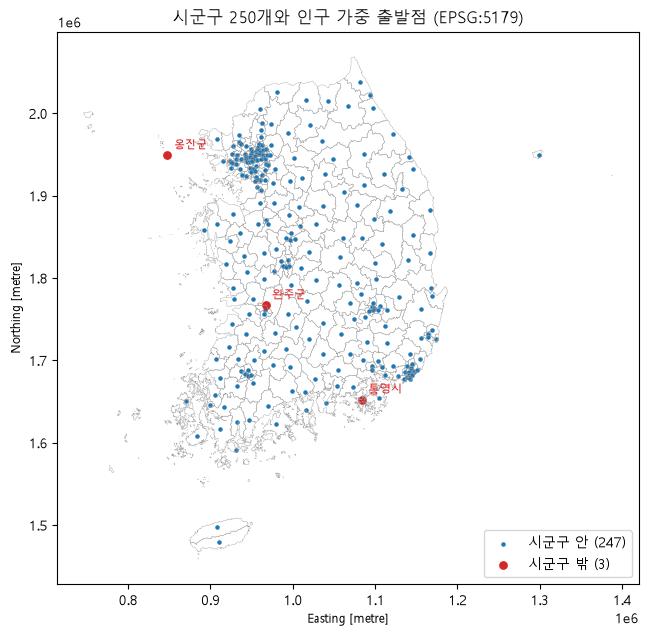

In [12]:
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
fig, ax = plt.subplots(figsize=(7.5, 9.5))
regions.boundary.plot(ax=ax, linewidth=0.25, color="0.6")
ok = origins[origins["inside_own"]]
ng = origins[~origins["inside_own"]]
ax.scatter(ok["x_m"], ok["y_m"], s=5, c="tab:blue", label=f"시군구 안 ({len(ok)})")
ax.scatter(ng["x_m"], ng["y_m"], s=28, c="tab:red", label=f"시군구 밖 ({len(ng)})")
for r in ng.itertuples():
    ax.annotate(r.name.split()[-1], (r.x_m, r.y_m), xytext=(5, 5), textcoords="offset points", fontsize=8, color="tab:red")
ax.set_aspect("equal")
ax.set_title("시군구 250개와 인구 가중 출발점 (EPSG:5179)")
ax.legend(loc="lower right")
plt.show()

## 7. B부분: 출발점 확정, 도로망, 섬 링크, 통행시간 행렬

A부분의 250개 단위 위에서 0S-2를 끝낸다. 곡률·임베딩은 하지 않는다.

- 7절: 출발점 확정. 출장소 인구를 이름이 같은 상위 읍면동에 얹고, 인구 가중 중심이 자기 시군구 밖이면 그 시군구에서 인구(출장소 포함)가 가장 많은 행정동의 대표점을 출발점으로 쓴다.
- 8절: 도로망(PLAN 6.1a 도로망 파이프라인).
- 9절: 전역 속도 계수 준비(검증 쌍 6개, 사용자 지도값 대기. 지금은 c = 1.0 잠정).
- 10절: 섬 링크(`island_links.csv`)와 강연결 최대 성분.
- 11절: 출발점 연결선, 통행시간 행렬, 진단.

In [13]:
import time

import duckdb
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, dijkstra
from scipy.spatial import cKDTree

T_B0 = time.time()
PBF = RAW / "geofabrik_20261018" / "south-korea-261017.osm.pbf"
PBF_SQL = PBF.as_posix()
print("OSM PBF:", PBF.name, "| MD5(manifest)", manifest.loc[manifest["path"].str.endswith(PBF.name), "md5"].iloc[0])
con = duckdb.connect()
con.execute("LOAD spatial")


def osm_centers(way_ids=(), node_ids=()):
    # OSM way(구성 노드 좌표의 평균)와 node의 (kind, id, name, lon, lat)를 돌려준다
    parts = []
    if len(way_ids):
        ids = ",".join(str(int(i)) for i in way_ids)
        parts.append(con.execute(f"""
            WITH w AS (SELECT id AS wid, tags['name'] AS nm, unnest(refs) AS rid FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'way' AND id IN ({ids}))
            SELECT 'way' AS kind, w.wid AS id, any_value(w.nm) AS name, avg(n.lon) AS lon, avg(n.lat) AS lat
            FROM w JOIN (SELECT id, lon, lat FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'node') n ON n.id = w.rid GROUP BY w.wid""").df())
    if len(node_ids):
        ids = ",".join(str(int(i)) for i in node_ids)
        parts.append(con.execute(f"""SELECT 'node' AS kind, id, tags['name'] AS name, lon, lat
            FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'node' AND id IN ({ids})""").df())
    return pd.concat(parts, ignore_index=True)

OSM PBF: south-korea-261017.osm.pbf | MD5(manifest) 355b718187224e6f85c7fd5b911c108f


### 7-1. 출장소 → 상위 읍면동 대응표

인구표에는 다각형이 없는 출장소 행이 63개(인구 0인 면 5개는 무시) 있다. 출장소 이름이 상위 읍면동 이름으로 시작하면(읍·면·동 글자를 뗀 앞부분 포함) 그 읍면동에 얹는다. 이름으로 못 찾는 2곳은 OSM 건물·해변 위치가 어느 읍면동 다각형 안에 있는지로 정하고, 노트북에서 그 증거를 다시 계산해 확인한다.

In [14]:
norm = lambda s: re.sub(r"\s+", "", s)
j["adm_nm_n"] = j["adm_nm"].map(norm)
branch = pop_no_poly[pop_no_poly["name"].str.endswith("출장소")].copy()
assert len(branch) == 63 and branch["pop"].sum() == pop_no_poly["pop"].sum()  # 인구 0인 면 5개는 인구 0이라 합이 같다


def parent_by_name(name, code):
    nn = norm(name)
    hits = []
    for c in j[j["sgg"] == code[:5]].itertuples():
        full = c.adm_nm_n
        stem = full[:-1] if full[-1] in "읍면동" else None
        if nn.startswith(full):
            hits.append((len(full), c.adm_cd2, c.adm_nm))
        elif stem and nn.startswith(stem):
            hits.append((len(stem), c.adm_cd2, c.adm_nm))
    if not hits:
        return None
    hits.sort(reverse=True)
    assert len(hits) == 1 or hits[0][0] > hits[1][0], (name, hits)  # 같은 길이로 겹치는 후보 없음
    return hits[0]


MANUAL = {  # 이름으로 못 찾는 출장소: (상위 읍면동 코드, 근거). 근거는 아래에서 OSM으로 다시 계산해 확인한다
    "4418032900": ("4418032000", "수동: OSM 오천면 행정복지센터 원산도출장소(way 1154526871)가 오천면 다각형 안"),
    "4824089000": ("4824051000", "수동: OSM 신수도몽돌해변(way 1460877771)이 동서동 다각형 안"),
}
EVIDENCE = {1154526871: "4418032000", 1460877771: "4824051000"}
ev = osm_centers(way_ids=list(EVIDENCE))
ev["x"], ev["y"] = TR.transform(ev["lon"].to_numpy(), ev["lat"].to_numpy())
poly_by_code = j.set_index("adm_cd2")["geometry"]
nm_by_code = j.set_index("adm_cd2")["adm_nm"]
for r in ev.itertuples():
    ok = poly_by_code[EVIDENCE[r.id]].covers(Point(r.x, r.y))
    print(f"수동 대응 증거: OSM way {r.id} '{r.name}' ({r.lon:.5f}, {r.lat:.5f}) -> {nm_by_code[EVIDENCE[r.id]]} 다각형 안: {ok}")
    assert ok

rows_b = []
for r in branch.itertuples():
    b = parent_by_name(r.name, r.code)
    if b is not None:
        rows_b.append((r.name, r.code, r.pop, b[2], b[1], "이름 앞부분이 같은 읍면동"))
    else:
        pc, why = MANUAL[r.code]
        rows_b.append((r.name, r.code, r.pop, nm_by_code[pc], pc, why))
bmap = pd.DataFrame(rows_b, columns=["branch_name", "branch_code", "pop", "parent_name", "parent_code", "rule"])
assert len(bmap) == 63 and bmap["parent_code"].isin(set(j["adm_cd2"])).all()
assert set(bmap.loc[bmap["rule"].str.startswith("수동"), "branch_code"]) == set(MANUAL)
print(f"\n출장소 63곳 모두 상위 읍면동을 찾음(이름 {int((~bmap['rule'].str.startswith('수동')).sum())}곳, 수동 {int(bmap['rule'].str.startswith('수동').sum())}곳), 얹는 인구 {bmap['pop'].sum():,}명")
show = bmap.assign(sigungu=bmap["parent_name"].str.split().str[:-1].str.join(" "), branch=bmap["branch_name"].str.split().str[-1],
                   parent=bmap["parent_name"].str.split().str[-1])
print(show[["sigungu", "branch", "parent", "pop", "rule"]].to_string(index=False))

수동 대응 증거: OSM way 1460877771 '신수도몽돌해변' (128.07537, 34.89299) -> 경상남도 사천시 동서동 다각형 안: True
수동 대응 증거: OSM way 1154526871 '오천면 행정복지센터 원산도출장소' (126.43220, 36.38023) -> 충청남도 보령시 오천면 다각형 안: True

출장소 63곳 모두 상위 읍면동을 찾음(이름 61곳, 수동 2곳), 얹는 인구 231,907명
    sigungu     branch parent   pop                                                 rule
  대구광역시 달성군   논공읍공단출장소    논공읍 10897                                       이름 앞부분이 같은 읍면동
  대구광역시 달성군   다사읍서재출장소    다사읍 37786                                       이름 앞부분이 같은 읍면동
  인천광역시 강화군   서도면볼음출장소    서도면   276                                       이름 앞부분이 같은 읍면동
  인천광역시 옹진군   북도면장봉출장소    북도면   950                                       이름 앞부분이 같은 읍면동
  인천광역시 옹진군   대청면소청출장소    대청면   235                                       이름 앞부분이 같은 읍면동
  인천광역시 옹진군   자월면이작출장소    자월면   362                                       이름 앞부분이 같은 읍면동
   경기도 남양주시   화도읍동부출장소    화도읍 12897                                       이름 앞부분이 같은 읍면동
   경기도 남양주시   화도읍남부출장소    화도읍 35308           

### 7-2. 출발점 규칙

1. 가중 중심: 행정동 대표점의 가중 평균. 가중치는 행정동 인구에 상위 읍면동으로 대응된 출장소 인구를 더한 값이다(단위별 가중치 합 = 시군구 총인구).
2. 가중 중심이 자기 시군구 다각형 밖이면, 그 시군구에서 가중치(인구, 출장소 포함)가 가장 큰 행정동의 대표점을 출발점으로 쓴다. 바뀐 단위와 이동 거리를 아래에 적고, 원래 중심은 참고 열(`x_wc_m`, `y_wc_m`)로 남긴다.

In [15]:
extra_by_parent = bmap.groupby("parent_code")["pop"].sum()
w_alloc = j["pop"].to_numpy(float) + j["adm_cd2"].map(extra_by_parent).fillna(0.0).to_numpy()
wsum = pd.Series(w_alloc).groupby(j["unit_code"].to_numpy()).sum().reindex(regions["unit_code"])
assert (wsum.to_numpy() == regions["pop_2025_12"].to_numpy()).all()
print(f"가중치 합 = 단위별 총인구(pop_2025_12): 250개 모두 일치 (출장소 인구 {int(extra_by_parent.sum()):,}명을 얹음)")

acc_w = pd.DataFrame({"unit_code": j["unit_code"].to_numpy(), "w": w_alloc, "wx": w_alloc * px, "wy": w_alloc * py}).groupby("unit_code").sum().reindex(regions["unit_code"])
wc_x, wc_y = (acc_w["wx"] / acc_w["w"]).to_numpy(), (acc_w["wy"] / acc_w["w"]).to_numpy()
wc_pts = shapely.points(wc_x, wc_y)
wc_inside = shapely.covers(reg_geoms, wc_pts)
wc_dist = shapely.distance(reg_geoms, wc_pts)
wc_other = []
for k, pt in enumerate(wc_pts):
    if wc_inside[k]:
        wc_other.append(None)
    else:
        hit = [regions["unit_code"].iloc[i] for i in regions.sindex.query(pt, predicate="intersects")]
        wc_other.append(hit[0] if hit else "바다·무소속")

# 가중 중심이 밖인 단위: 가중치가 가장 큰 행정동의 대표점
idx_big = pd.Series(w_alloc).groupby(j["unit_code"].to_numpy()).idxmax().reindex(regions["unit_code"]).to_numpy()
big_x, big_y = px[idx_big], py[idx_big]
big_name, big_w = j["adm_nm"].to_numpy()[idx_big], w_alloc[idx_big]
fx, fy = np.where(wc_inside, wc_x, big_x), np.where(wc_inside, wc_y, big_y)
final_pts = shapely.points(fx, fy)
assert shapely.covers(reg_geoms, final_pts).all(), "최종 출발점이 자기 시군구 밖"
moved = np.hypot(fx - wc_x, fy - wc_y)

origins_a = origins  # A부분 결과(다각형이 붙은 행정동만 가중, 출장소 제외)
origins = gpd.GeoDataFrame(
    {"idx": regions["idx"].to_numpy(), "unit_code": regions["unit_code"].to_numpy(), "name": regions["name"].to_numpy(),
     "pop_2025_12": regions["pop_2025_12"].to_numpy(), "pop_matched": regions["pop_matched"].to_numpy(),
     "matched_share": regions["matched_share"].to_numpy(), "n_dong_used": pd.Series(w_alloc > 0).groupby(j["unit_code"].to_numpy()).sum().reindex(regions["unit_code"]).to_numpy(),
     "x_m": fx, "y_m": fy,
     "origin_rule": np.where(wc_inside, "pop_weighted_center", "largest_dong_rep_point"),
     "origin_dong": np.where(wc_inside, None, big_name),
     "x_wc_m": wc_x, "y_wc_m": wc_y, "wc_inside_own": wc_inside, "wc_dist_to_own_m": wc_dist, "wc_in_other_unit": wc_other, "moved_m": moved,
     "x_matched_m": origins_a["x_m"].to_numpy(), "y_matched_m": origins_a["y_m"].to_numpy(),
     "shift_alloc_m": np.hypot(wc_x - origins_a["x_m"].to_numpy(), wc_y - origins_a["y_m"].to_numpy())},
    geometry=final_pts, crs=CRS_WORK)

print(f"\n출발점 규칙: {origins['origin_rule'].value_counts().to_dict()}")
chg = origins[~origins["wc_inside_own"]].copy()
chg["가중중심_밖_이웃"] = chg["wc_in_other_unit"].map(lambda c: name_of.get(c, c))
chg["이동거리_km"] = chg["moved_m"] / 1000
chg["대표 행정동 가중치"] = big_w[~wc_inside].astype(int)
print("바뀐 단위(가중 중심이 자기 시군구 밖):")
print(chg[["unit_code", "name", "origin_dong", "대표 행정동 가중치", "wc_dist_to_own_m", "가중중심_밖_이웃", "이동거리_km"]].to_string(
    index=False, formatters={"wc_dist_to_own_m": "{:,.0f}".format, "이동거리_km": "{:,.1f}".format}))
print(f"\n출장소 인구를 얹은 효과(A부분 중심 대비 가중 중심 이동량 m): 중앙값 {origins['shift_alloc_m'].median():.1f}, 최대 {origins['shift_alloc_m'].max():,.0f}, 500 m 넘는 단위 {int((origins['shift_alloc_m'] > 500).sum())}개")

origins.to_parquet(OUT / "origins.parquet", index=False)
o3 = gpd.read_parquet(OUT / "origins.parquet")
assert len(o3) == 250 and o3.crs.to_epsg() == 5179 and shapely.covers(reg_geoms, o3.geometry.to_numpy()).all()
print("저장:", OUT / "origins.parquet", "| 열", list(o3.columns))

가중치 합 = 단위별 총인구(pop_2025_12): 250개 모두 일치 (출장소 인구 231,907명을 얹음)

출발점 규칙: {'pop_weighted_center': 246, 'largest_dong_rep_point': 4}
바뀐 단위(가중 중심이 자기 시군구 밖):
unit_code        name     origin_dong  대표 행정동 가중치 wc_dist_to_own_m       가중중심_밖_이웃 이동거리_km
    28720   인천광역시 옹진군   인천광역시 옹진군 영흥면        6483           11,397          바다·무소속    65.4
    46910    전라남도 신안군    전라남도 신안군 압해읍        6967               81          바다·무소속    21.3
    48220    경상남도 통영시    경상남도 통영시 광도면       31719               83          바다·무소속     6.3
    52710 전북특별자치도 완주군 전북특별자치도 완주군 봉동읍       24355              248 전북특별자치도 전주시 덕진구     5.8

출장소 인구를 얹은 효과(A부분 중심 대비 가중 중심 이동량 m): 중앙값 0.0, 최대 2,807, 500 m 넘는 단위 13개
저장: C:\dev\kfm-data\spike\origins.parquet | 열 ['idx', 'unit_code', 'name', 'pop_2025_12', 'pop_matched', 'matched_share', 'n_dong_used', 'x_m', 'y_m', 'origin_rule', 'origin_dong', 'x_wc_m', 'y_wc_m', 'wc_inside_own', 'wc_dist_to_own_m', 'wc_in_other_unit', 'moved_m', 'x_matched_m', 'y_matched_m', 'shift_alloc_m', '

## 8. 도로망 (PLAN 6.1a 도로망 파이프라인)

- 필터: `highway` ∈ motorway, trunk, primary, secondary, tertiary와 각 `_link`, unclassified, residential, living_street. `area=yes`, `access` ∈ {private, no}, `motor_vehicle=no`, `motorcar=no`는 뺀다.
- 단순화: way에서 2회 이상 쓰인 노드와 way 끝점만 그래프 노드로 두고, 그 사이 구간을 엣지 하나로 합친다. 길이는 EPSG:5179 평면 거리(pyproj `always_xy=True`).
- 방향: `oneway` ∈ {yes, true, 1} 순방향, {-1, reverse} 역방향, `junction` ∈ {roundabout, circular} 순방향, `highway=motorway`는 `oneway=no`가 아니면 순방향. 회전 제한은 무시한다.
- 속도: 숫자 `maxspeed`, 없으면 같은 파일의 등급별 `maxspeed` 평균(단순화 엣지 단위 평균). 자유류 시간 = 길이 / 속도.
- 희소 행렬: 같은 (u, v) 중복 엣지는 최솟값으로 줄이고, 0 가중치에는 하한 1e-6분을 둔다.

In [16]:
# 8-1. DuckDB spatial ST_ReadOSM으로 읽기·필터·단순화
MAIN_HW = ["motorway", "trunk", "primary", "secondary", "tertiary"]
HW = MAIN_HW + [h + "_link" for h in MAIN_HW] + ["unclassified", "residential", "living_street"]
hw_sql = ",".join(f"'{h}'" for h in HW)
t0 = time.time()
con.execute(f"""CREATE OR REPLACE TABLE dw AS SELECT id AS way_id, tags['highway'] AS hw, tags['oneway'] AS ow, tags['junction'] AS jn, tags['maxspeed'] AS ms, refs
    FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'way' AND tags['highway'] IN ({hw_sql})
    AND coalesce(tags['area'], 'no') <> 'yes'
    AND coalesce(tags['access'], '') NOT IN ('private', 'no')
    AND coalesce(tags['motor_vehicle'], '') <> 'no' AND coalesce(tags['motorcar'], '') <> 'no'""")
con.execute("CREATE OR REPLACE TABLE wn AS SELECT way_id, unnest(refs) AS node_id, generate_subscripts(refs, 1) AS seq, len(refs) AS n FROM dw")
con.execute("CREATE OR REPLACE TABLE nu AS SELECT node_id, count(*) AS c FROM wn GROUP BY node_id")
con.execute(f"CREATE OR REPLACE TABLE nd AS SELECT id AS node_id, lat, lon FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'node' AND id IN (SELECT node_id FROM nu)")
con.execute("""CREATE OR REPLACE TABLE wn2 AS SELECT wn.way_id, wn.seq, wn.node_id, nd.lat, nd.lon, (nu.c >= 2 OR wn.seq = 1 OR wn.seq = wn.n) AS is_g
    FROM wn JOIN nu USING (node_id) JOIN nd USING (node_id)""")
n_refs = con.execute("SELECT count(*) FROM wn").fetchone()[0]
vtx = con.execute("SELECT way_id, seq, node_id, lat, lon, is_g FROM wn2 ORDER BY way_id, seq").df()
ways = con.execute("SELECT way_id, hw, ow, jn, ms FROM dw").df()
for t in ("wn2", "nd", "nu", "wn", "dw"):
    con.execute(f"DROP TABLE {t}")
t_duck = time.time() - t0
assert len(vtx) == n_refs, "좌표가 없는 노드 참조가 있다"

# EPSG:5179 평면 길이(pyproj always_xy=True): 같은 way의 이웃 꼭짓점 사이 거리를 모아 그래프 노드 사이 엣지 길이로 만든다
t0 = time.time()
trf = pyproj.Transformer.from_crs("EPSG:4326", CRS_WORK, always_xy=True)
vx, vy = trf.transform(vtx["lon"].to_numpy(), vtx["lat"].to_numpy())
wid, nid, isg = vtx["way_id"].to_numpy(), vtx["node_id"].to_numpy(), vtx["is_g"].to_numpy()
seg = np.zeros(len(vtx))
seg[:-1] = np.hypot(vx[1:] - vx[:-1], vy[1:] - vy[:-1])
seg[np.r_[wid[1:] != wid[:-1], True]] = 0.0  # way의 마지막 꼭짓점에서 다음 way로 넘어가는 선분은 없다
cum0 = np.r_[0.0, np.cumsum(seg)]
ig = np.flatnonzero(isg)
same_way = wid[ig[:-1]] == wid[ig[1:]]
a, b = ig[:-1][same_way], ig[1:][same_way]
edges_u = pd.DataFrame({"way_id": wid[a], "u": nid[a], "v": nid[b], "length_m": cum0[b] - cum0[a]}).merge(ways, on="way_id", how="left")
nodes_road = pd.DataFrame({"node_id": nid[ig], "lon": vtx["lon"].to_numpy()[ig], "lat": vtx["lat"].to_numpy()[ig], "x_m": vx[ig], "y_m": vy[ig]}).drop_duplicates("node_id").reset_index(drop=True)
t_len = time.time() - t0

# 길이 점검: 표본 way의 EPSG:5179 합과 측지 거리(GRS80 타원체) 비교
geod = pyproj.Geod(ellps="GRS80")
rng = np.random.default_rng(0)
sample = rng.choice(np.unique(wid), size=500, replace=False)
lon_a, lat_a = vtx["lon"].to_numpy(), vtx["lat"].to_numpy()
rel = []
for wy in sample:
    lo, hi = np.searchsorted(wid, wy, "left"), np.searchsorted(wid, wy, "right")  # vtx는 way_id 순으로 정렬돼 있다
    if hi - lo < 2:
        continue
    d_geo = geod.line_length(lon_a[lo:hi], lat_a[lo:hi])
    d_pl = seg[lo:hi].sum()
    if d_geo > 0:
        rel.append(d_pl / d_geo - 1)
rel = np.array(rel)
del vtx, vx, vy, wid, nid, isg, seg, cum0

print(f"필터 통과 way {len(ways):,}개 | 노드 참조 {n_refs:,}개 | 그래프 노드 {len(nodes_road):,}개 | 단순화 엣지(무방향) {len(edges_u):,}개 (자기 루프 {int((edges_u['u'] == edges_u['v']).sum()):,}개)")
print(f"총 길이 {edges_u['length_m'].sum() / 1000:,.0f} km | EPSG:5179 길이 / 측지 길이 - 1: 중앙값 {np.median(rel):+.4%}, 5~95% [{np.quantile(rel, .05):+.4%}, {np.quantile(rel, .95):+.4%}] (way 표본 {len(rel)}개)")
print(f"실행 시간: DuckDB 구성 {t_duck:.1f}초, 길이 계산 {t_len:.1f}초")

필터 통과 way 761,959개 | 노드 참조 7,693,710개 | 그래프 노드 1,086,323개 | 단순화 엣지(무방향) 1,433,942개 (자기 루프 1,225개)
총 길이 231,508 km | EPSG:5179 길이 / 측지 길이 - 1: 중앙값 -0.0357%, 5~95% [-0.0400%, -0.0127%] (way 표본 500개)
실행 시간: DuckDB 구성 2.8초, 길이 계산 1.1초


In [17]:
# 8-2. 속도, 방향, 중복 최솟값, 희소 행렬, 강연결 성분
t0 = time.time()
num = pd.to_numeric(edges_u["ms"].str.extract(r"^\s*(\d+(?:\.\d+)?)\s*$")[0], errors="coerce")
cls_mean = num.groupby(edges_u["hw"]).mean()
PLAN_REF = {"motorway": 101, "trunk": 78, "primary": 63, "secondary": 56, "tertiary": 50, "unclassified": 37, "residential": 33}
tab = pd.DataFrame({"edges": edges_u.groupby("hw").size(), "maxspeed_numeric": num.groupby(edges_u["hw"]).count(), "class_mean_kmh": cls_mean})
tab["fill_rate"] = tab["maxspeed_numeric"] / tab["edges"]
tab["PLAN_6.1a"] = pd.Series(PLAN_REF)
print("[속도] 숫자 maxspeed 채움률과 등급별 평균(없는 엣지에 쓰는 값)")
print(tab.loc[HW].round({"class_mean_kmh": 1, "fill_rate": 3}).to_string())
edges_u["speed_kmh"] = num.where(num.notna(), edges_u["hw"].map(cls_mean)).astype(float)
edges_u["speed_src"] = np.where(num.notna(), "maxspeed", "class_mean")
assert edges_u["speed_kmh"].notna().all() and (edges_u["speed_kmh"] > 0).all()
edges_u["t_min"] = edges_u["length_m"] / 1000 / edges_u["speed_kmh"] * 60

ow, jn = edges_u["ow"].fillna(""), edges_u["jn"].fillna("")
rev_only = ow.isin(["-1", "reverse"])
fwd_only = (~rev_only) & (ow.isin(["yes", "true", "1"]) | jn.isin(["roundabout", "circular"]) | ((edges_u["hw"] == "motorway") & (ow != "no")))
print(f"\n[방향] 순방향만 {int(fwd_only.sum()):,}개, 역방향만 {int(rev_only.sum()):,}개, 양방향 {int((~fwd_only & ~rev_only).sum()):,}개 (무방향 엣지 기준)")
cols = ["way_id", "u", "v", "length_m", "hw", "speed_kmh", "speed_src", "t_min"]
de = pd.concat([edges_u.loc[~rev_only, cols], edges_u.loc[~fwd_only, cols].rename(columns={"u": "v", "v": "u"})], ignore_index=True)
n_raw = len(de)
de = de[de["u"] != de["v"]]
n_noloop = len(de)
de = de.sort_values(["t_min", "length_m"], kind="stable").drop_duplicates(["u", "v"], keep="first").reset_index(drop=True)
print(f"방향 엣지 {n_raw:,}개 -> 자기 루프 제거 {n_noloop:,}개 -> 같은 (u, v) 중복을 최솟값으로 줄임 {len(de):,}개 (0 가중치 엣지 {int((de['t_min'] < 1e-6).sum())}개)")

node_ix = pd.Index(nodes_road["node_id"].to_numpy())
ui, vi = node_ix.get_indexer(de["u"].to_numpy()), node_ix.get_indexer(de["v"].to_numpy())
assert (ui >= 0).all() and (vi >= 0).all()
N = len(nodes_road)
xy = np.c_[nodes_road["x_m"].to_numpy(), nodes_road["y_m"].to_numpy()]
t_base = de["t_min"].to_numpy()
G_road = csr_matrix((np.maximum(t_base, 1e-6), (ui, vi)), shape=(N, N))
assert G_road.nnz == len(de), "csr가 중복 엣지를 더했다"
n_comp, lab_road = connected_components(G_road, directed=True, connection="strong")
sizes = np.bincount(lab_road)
order = np.argsort(-sizes)
nodes_road["scc_road"] = lab_road
nodes_road["scc_road_size"] = sizes[lab_road]
print(f"\n[연결성] 노드 {N:,}개, 방향 엣지 {G_road.nnz:,}개, 강연결 성분 {n_comp:,}개, 최대 성분 {sizes[order[0]]:,}개 ({sizes[order[0]] / N:.2%})")
for k in order[:6]:
    m = lab_road == k
    print(f"  성분 {k}: 노드 {sizes[k]:,}개, 경도 {nodes_road['lon'][m].min():.2f}~{nodes_road['lon'][m].max():.2f}, 위도 {nodes_road['lat'][m].min():.2f}~{nodes_road['lat'][m].max():.2f}")

de_out = de[["way_id", "u", "v", "length_m", "hw", "speed_kmh", "speed_src", "t_min"]].rename(columns={"t_min": "t_min_base"})
de_out.to_parquet(OUT / "road_edges.parquet", index=False)
print(f"저장: {OUT / 'road_edges.parquet'} ({(OUT / 'road_edges.parquet').stat().st_size / 1e6:.0f} MB, 방향 엣지 {len(de_out):,}개, t_min_base = 계수 c를 곱하기 전 자유류 시간) | 실행 시간 {time.time() - t0:.1f}초")

[속도] 숫자 maxspeed 채움률과 등급별 평균(없는 엣지에 쓰는 값)
                 edges  maxspeed_numeric  class_mean_kmh  fill_rate  PLAN_6.1a
hw                                                                            
motorway         23236             22353           101.0      0.962      101.0
trunk            35175             18306            78.0      0.520       78.0
primary          75384             19225            63.0      0.255       63.0
secondary       127072             17293            56.4      0.136       56.0
tertiary        208373             17003            49.5      0.082       50.0
motorway_link    13505              4570            48.5      0.338        NaN
trunk_link       21466              1963            47.2      0.091        NaN
primary_link     16728               876            46.0      0.052        NaN
secondary_link   13513               549            37.3      0.041        NaN
tertiary_link    11083               347            34.0      0.031        NaN
unclassifi


[방향] 순방향만 286,754개, 역방향만 742개, 양방향 1,146,446개 (무방향 엣지 기준)


방향 엣지 2,580,388개 -> 자기 루프 제거 2,578,069개 -> 같은 (u, v) 중복을 최솟값으로 줄임 2,562,553개 (0 가중치 엣지 0개)



[연결성] 노드 1,086,323개, 방향 엣지 2,562,553개, 강연결 성분 7,007개, 최대 성분 1,033,379개 (95.13%)
  성분 862: 노드 1,033,379개, 경도 125.98~129.58, 위도 34.29~38.61
  성분 876: 노드 29,294개, 경도 126.16~126.94, 위도 33.20~33.56
  성분 957: 노드 442개, 경도 124.61~124.74, 위도 37.92~37.98
  성분 890: 노드 423개, 경도 130.80~130.92, 위도 37.46~37.55
  성분 883: 노드 412개, 경도 125.90~126.01, 위도 34.67~34.79
  성분 974: 노드 403개, 경도 126.50~126.64, 위도 34.13~34.23


저장: C:\dev\kfm-data\spike\road_edges.parquet (72 MB, 방향 엣지 2,562,553개, t_min_base = 계수 c를 곱하기 전 자유류 시간) | 실행 시간 3.2초


## 9. 전역 속도 계수 준비 (사용자 지도값 대기)

검증 쌍 6개의 출발·도착 청사 좌표를 OSM에서 이름으로 찾고, 가장 가까운 도로 노드 사이의 모델 시간(계수 1)을 낸다. 사용자가 지도 서비스의 값(혼잡 적은 시간대, 조회 일시 기록)을 `MAP_TIME_MIN`에 넣고 노트북을 다시 실행하면 `c = exp(mean(log(지도값 / 모델값)))`가 정해지고 11절의 행렬이 다시 만들어진다. c는 도로 엣지 시간에만 곱하고 섬 링크 시간에는 곱하지 않는다.

OSM에서 `amenity=townhall`로 찾은 청사는 충주·강릉·전주·포항뿐이었다. 나머지는 이름이 같은 `office=government`·`building=government|public` 건물(또는 노드)을 쓰고, 대전 중구청은 건물이 없어 '중구청' 버스 정류장 2곳의 평균을 임시로 썼다(근거 열 참조). 모든 청사는 기대한 시군구 다각형 안에 있는지 확인한다.

In [18]:
# 청사: (OSM kind, id 목록, 기대 시군구 unit_code, 근거)
HALLS = {
    "서울 종로구청": ("way", [1215689838], "11110", "name='종로구청 복합청사', amenity 태그 없음"),
    "부산 중구청": ("way", [780093689], "26110", "name='중구청', office=government"),
    "강릉시청": ("node", [11687596361], "51150", "amenity=townhall"),
    "대전 중구청": ("node", [10697690243, 11338182355], "30140", "임시: 건물 없음, '중구청' 버스 정류장 2곳 평균"),
    "대구 중구청": ("way", [886649528], "27110", "name='중구청', office=government"),
    "광주 동구청": ("way", [484710192], "29110", "name='동구청', office=government"),
    "전주시청": ("way", [36811470], "52111", "amenity=townhall"),
    "청주시청": ("node", [282684005], "43111", "name='청주시청', office=government"),
    "충주시청": ("node", [358015384], "43130", "amenity=townhall"),
    "안동시청": ("way", [547432915], "47170", "name='안동시청', building=public"),
    "포항시청": ("way", [469052482], "47111", "amenity=townhall (포항시 남구)"),
}
PAIRS = [("서울 종로구청", "부산 중구청"), ("서울 종로구청", "강릉시청"), ("대전 중구청", "대구 중구청"),
         ("광주 동구청", "전주시청"), ("청주시청", "충주시청"), ("안동시청", "포항시청")]
way_ids = [i for k, ids, _, _ in HALLS.values() if k == "way" for i in ids]
node_ids = [i for k, ids, _, _ in HALLS.values() if k == "node" for i in ids]
oc = osm_centers(way_ids=way_ids, node_ids=node_ids).set_index(["kind", "id"])
reg_by_code = regions.set_index("unit_code")
hall_rows = []
for label, (kind, ids, unit, basis) in HALLS.items():
    pts_ll = np.array([[oc.loc[(kind, i), "lon"], oc.loc[(kind, i), "lat"]] for i in ids])
    lon, lat = pts_ll[:, 0].mean(), pts_ll[:, 1].mean()
    hx, hy = TR.transform(lon, lat)
    inside_exp = reg_by_code.loc[unit, "geometry"].covers(Point(hx, hy))
    hall_rows.append({"hall": label, "osm": f"{kind} {'+'.join(map(str, ids))}", "osm_name": ";".join(str(oc.loc[(kind, i), "name"]) for i in ids),
                      "basis": basis, "lon": lon, "lat": lat, "x_m": hx, "y_m": hy, "unit": unit, "in_unit": inside_exp})
halls = pd.DataFrame(hall_rows).set_index("hall")
assert halls["in_unit"].all(), halls.loc[~halls["in_unit"]].index.tolist()
main_road = int(np.argmax(sizes))
keep0 = np.flatnonzero(lab_road == main_road)
tree0 = cKDTree(xy[keep0])
d_h, k_h = tree0.query(halls[["x_m", "y_m"]].to_numpy())
halls["node_id"] = nodes_road["node_id"].to_numpy()[keep0[k_h]]
halls["snap_m"] = d_h
print("[청사 좌표] OSM에서 찾은 위치(EPSG:4326, 5179)와 가장 가까운 도로 노드(최대 성분) 거리")
print(halls[["osm", "osm_name", "basis", "lon", "lat", "x_m", "y_m", "in_unit", "node_id", "snap_m"]].to_string(
    formatters={"lon": "{:.6f}".format, "lat": "{:.6f}".format, "x_m": "{:,.1f}".format, "y_m": "{:,.1f}".format, "snap_m": "{:,.0f}".format}))

[청사 좌표] OSM에서 찾은 위치(EPSG:4326, 5179)와 가장 가까운 도로 노드(최대 성분) 거리
                                  osm   osm_name                            basis        lon       lat         x_m         y_m  in_unit     node_id snap_m
hall                                                                                                                                                      
서울 종로구청                way 1215689838  종로구청 복합청사  name='종로구청 복합청사', amenity 태그 없음 126.979330 37.572760   954,022.5 1,952,726.0     True  2064459568     34
부산 중구청                  way 780093689        중구청    name='중구청', office=government 129.032357 35.106283 1,139,654.8 1,680,088.6     True  4928310006     28
강릉시청                 node 11687596361       강릉시청                 amenity=townhall 128.875865 37.751937 1,121,205.9 1,973,368.5     True  3622666941    211
대전 중구청   node 10697690243+11338182355    중구청;중구청    임시: 건물 없음, '중구청' 버스 정류장 2곳 평균 127.421692 36.325682   992,971.5 1,814,260.2     True  1133396652     36
대구 중구청   

In [19]:
# 모델 시간(계수 1): 도로 그래프 최대 성분 위에서 청사 최근접 노드 사이의 최단 시간. 경로 길이·평균 속도도 함께 낸다
Gm0 = G_road[keep0][:, keep0]
Lm0 = csr_matrix((de["length_m"].to_numpy(), (ui, vi)), shape=(N, N))[keep0][:, keep0]
pos0 = {int(n): i for i, n in enumerate(keep0)}
src_nodes = sorted({pos0[int(node_ix.get_loc(halls.loc[a, "node_id"]))] for a, _ in PAIRS})
t_src, pred_src = dijkstra(Gm0, directed=True, indices=src_nodes, return_predecessors=True)
row_of = {s: r for r, s in enumerate(src_nodes)}
pair_rows = []
for a, b in PAIRS:
    s, t = pos0[int(node_ix.get_loc(halls.loc[a, "node_id"]))], pos0[int(node_ix.get_loc(halls.loc[b, "node_id"]))]
    r = row_of[s]
    path, cur = [t], t
    while cur != s:
        cur = pred_src[r, cur]
        path.append(cur)
    path = path[::-1]
    route_km = sum(Lm0[path[i], path[i + 1]] for i in range(len(path) - 1)) / 1000
    straight_km = np.hypot(halls.loc[a, "x_m"] - halls.loc[b, "x_m"], halls.loc[a, "y_m"] - halls.loc[b, "y_m"]) / 1000
    pair_rows.append({"pair": f"{a} → {b}", "straight_km": straight_km, "route_km": route_km, "model_min": t_src[r, t], "avg_kmh": route_km / t_src[r, t] * 60})
pairs = pd.DataFrame(pair_rows).set_index("pair")
print("[검증 쌍] 계수 c = 1 모델 시간 (도로 엣지만, 청사 최근접 노드 사이, 연결선 없음)")
print(pairs.to_string(formatters={"straight_km": "{:.1f}".format, "route_km": "{:.1f}".format, "model_min": "{:.1f}".format, "avg_kmh": "{:.1f}".format}))

# 사용자가 채우는 값: 지도 서비스 소요시간(분, 혼잡 적은 시간대). 조회 서비스와 일시를 MAP_QUERY_NOTE에 적는다.
MAP_TIME_MIN = {
    "서울 종로구청 → 부산 중구청": 262,
    "서울 종로구청 → 강릉시청": 147,
    "대전 중구청 → 대구 중구청": 102,
    "광주 동구청 → 전주시청": 76,
    "청주시청 → 충주시청": 58,
    "안동시청 → 포항시청": 84,
}
MAP_QUERY_NOTE = "네이버 지도 자동차 나중에 출발 예측, 2026-10-19 조회, 2026-10-20 출발(1·2번 05:00, 3번 05:50, 4–6번 04:50)"  # 예: "네이버 지도 자동차, 2026-10-21 화 10:30 출발 기준"
assert list(MAP_TIME_MIN) == list(pairs.index)

pairs["map_min"] = pd.Series(MAP_TIME_MIN).astype(float)  # None -> NaN
have_map = bool(pairs["map_min"].notna().all())
if have_map:
    pairs["ratio"] = pairs["map_min"] / pairs["model_min"]
if SPEED_FACTOR_C_OVERRIDE is not None:
    C_FACTOR, C_SOURCE = float(SPEED_FACTOR_C_OVERRIDE), "수동 지정(SPEED_FACTOR_C_OVERRIDE)"
elif have_map:
    C_FACTOR = float(np.exp(np.mean(np.log(pairs["ratio"]))))
    C_SOURCE = f"검증 쌍 6개 지도값({MAP_QUERY_NOTE or '조회 일시 미기록'})으로 계산"
else:
    C_FACTOR, C_SOURCE = 1.0, "잠정(지도값 미입력)"
assert C_FACTOR > 0
print(f"\n전역 속도 계수 c = {C_FACTOR:.4f} ({C_SOURCE})")
if have_map:
    pairs["after_c_min"] = pairs["model_min"] * C_FACTOR
    pairs["err_pct"] = (pairs["after_c_min"] / pairs["map_min"] - 1) * 100
    print(pairs[["model_min", "map_min", "ratio", "after_c_min", "err_pct"]].to_string(float_format=lambda v: f"{v:.2f}"))

[검증 쌍] 계수 c = 1 모델 시간 (도로 엣지만, 청사 최근접 노드 사이, 연결선 없음)
                 straight_km route_km model_min avg_kmh
pair                                                   
서울 종로구청 → 부산 중구청       329.8    399.4     241.3    99.3
서울 종로구청 → 강릉시청         168.5    215.6     142.6    90.7
대전 중구청 → 대구 중구청        118.0    147.3      95.1    92.9
광주 동구청 → 전주시청           78.0    103.1      73.2    84.4
청주시청 → 충주시청             54.9     66.5      52.6    75.9
안동시청 → 포항시청             82.2    120.0      84.8    84.9

전역 속도 계수 c = 1.0527 (검증 쌍 6개 지도값(네이버 지도 자동차 나중에 출발 예측, 2026-10-19 조회, 2026-10-20 출발(1·2번 05:00, 3번 05:50, 4–6번 04:50))으로 계산)
                  model_min  map_min  ratio  after_c_min  err_pct
pair                                                             
서울 종로구청 → 부산 중구청     241.33   262.00   1.09       254.06    -3.03
서울 종로구청 → 강릉시청       142.57   147.00   1.03       150.08     2.10
대전 중구청 → 대구 중구청       95.10   102.00   1.07       100.12    -1.85
광주 동구청 → 전주시청         73.24    76.00   1.04

## 10. 섬 링크와 강연결 최대 성분

`notebooks/spike/island_links.csv`(초안, 사용자 확인 대기)를 읽는다. 링크마다 두 끝점을 도로 그래프에서 가장 가까운 노드(크기 100 이상의 강연결 성분)에 붙이고, 양방향 엣지(시간 = `travel_min + wait_min`)를 더한다. 대기 시간은 가정값이다. 섬 링크 시간에는 속도 계수 c를 곱하지 않는다.

In [20]:
LINKS_PATH = Path("island_links.csv")
assert LINKS_PATH.exists(), "notebooks/spike 폴더에서 실행해야 한다"
links = pd.read_csv(LINKS_PATH, encoding="utf-8-sig")
assert list(links.columns) == ["from_name", "from_lon", "from_lat", "to_name", "to_lon", "to_lat", "mode", "travel_min", "wait_min",
                               "source_url", "retrieved_at", "note"]
assert links["mode"].isin(["ferry", "air"]).all()
links["link_min"] = links["travel_min"] + links["wait_min"]
# 대기 시간이 첫 셀의 가정값과 같은지 확인(다르면 사용자가 값을 바꾼 것이므로 알린다)
wait_expected = links["mode"].map({"ferry": FERRY_WAIT_MIN, "air": AIR_WAIT_MIN})
if not (links["wait_min"] == wait_expected).all():
    print("주의: island_links.csv의 wait_min이 첫 셀 가정값(배 %.0f, 항공 %.0f)과 다르다 -> CSV 값을 쓴다" % (FERRY_WAIT_MIN, AIR_WAIT_MIN))
print("[섬 링크 초안] island_links.csv 전체 행 (note는 파일 참조)")
print(links[["from_name", "to_name", "mode", "travel_min", "wait_min", "link_min", "retrieved_at"]].to_string(index=False))
for r in links.itertuples():
    print(f"  - {r.from_name} -> {r.to_name}: {r.source_url}")

big_mask = nodes_road["scc_road_size"].to_numpy() >= 100
idx_bigcomp = np.flatnonzero(big_mask)
tree_bigcomp = cKDTree(xy[big_mask])


def snap_big(lon, lat):
    x, y = TR.transform(lon, lat)
    d, k = tree_bigcomp.query([x, y])
    ni = int(idx_bigcomp[k])
    return ni, float(d), int(nodes_road["scc_road_size"].iloc[ni])


end_rows = []
for r in links.itertuples():
    for side, nm, lon, lat in (("from", r.from_name, r.from_lon, r.from_lat), ("to", r.to_name, r.to_lon, r.to_lat)):
        ni, d, comp = snap_big(lon, lat)
        end_rows.append({"link": f"{r.from_name} - {r.to_name}", "side": side, "name": nm, "node_id": int(nodes_road['node_id'].iloc[ni]), "snap_m": d, "component_nodes": comp, "node_ix": ni})
ends = pd.DataFrame(end_rows)
print("\n[끝점 -> 도로 노드] 크기 100 이상의 강연결 성분에서 가장 가까운 노드")
print(ends[["link", "side", "name", "node_id", "snap_m", "component_nodes"]].to_string(index=False, formatters={"snap_m": "{:,.0f}".format}))
assert (ends["snap_m"] < 2000).all()

[섬 링크 초안] island_links.csv 전체 행 (note는 파일 참조)
      from_name       to_name  mode  travel_min  wait_min  link_min retrieved_at
   김포국제공항 국내선청사        제주국제공항   air          75        90       165   2026-10-19
완도연안여객선터미널(완도항)    제주항연안여객터미널 ferry         160        60       220   2026-10-19
       포항여객선터미널 울릉항여객선터미널(사동) ferry         170        60       230   2026-10-19
  - 김포국제공항 국내선청사 -> 제주국제공항: https://www.airport.co.kr/gimpo/cms/frCon/index.do?MENU_ID=1060
  - 완도연안여객선터미널(완도항) -> 제주항연안여객터미널: https://www.hanilexpress.co.kr/service/sailingSchedule.do
  - 포항여객선터미널 -> 울릉항여객선터미널(사동): https://www.daezer.com/about/ship-infomation.html

[끝점 -> 도로 노드] 크기 100 이상의 강연결 성분에서 가장 가까운 노드
                        link side            name    node_id snap_m  component_nodes
       김포국제공항 국내선청사 - 제주국제공항 from    김포국제공항 국내선청사 2290159243    423          1033379
       김포국제공항 국내선청사 - 제주국제공항   to          제주국제공항 1103024461    367            29294
완도연안여객선터미널(완도항) - 제주항연안여객터미널 from 완도연안여객선터미널(완도항)  436747113    

In [21]:
# OSM 항로(route=ferry)는 대조용: 섬 링크 끝점 근처에서 출발·도착하는 OSM 항로의 duration 태그와 모형 값을 나란히 본다
con.execute(f"""CREATE OR REPLACE TABLE fw AS SELECT id AS way_id, tags['name'] AS nm, tags['duration'] AS dur, tags['operator'] AS op, refs
    FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'way' AND tags['route'] = 'ferry'""")
con.execute("CREATE OR REPLACE TABLE fwn AS SELECT way_id, unnest(refs) AS node_id, generate_subscripts(refs, 1) AS seq FROM fw")
con.execute(f"CREATE OR REPLACE TABLE fnd AS SELECT id AS node_id, lat, lon FROM ST_ReadOSM('{PBF_SQL}') WHERE kind = 'node' AND id IN (SELECT node_id FROM fwn)")
fe = con.execute("""SELECT f.way_id, any_value(fw.nm) AS nm, any_value(fw.dur) AS dur, any_value(fw.op) AS op,
        arg_min(d.lon, f.seq) AS a_lon, arg_min(d.lat, f.seq) AS a_lat, arg_max(d.lon, f.seq) AS b_lon, arg_max(d.lat, f.seq) AS b_lat
    FROM fwn f JOIN fnd d USING (node_id) JOIN fw ON fw.way_id = f.way_id GROUP BY f.way_id""").df()
for t in ("fnd", "fwn", "fw"):
    con.execute(f"DROP TABLE {t}")
fe["ax"], fe["ay"] = TR.transform(fe["a_lon"].to_numpy(), fe["a_lat"].to_numpy())
fe["bx"], fe["by"] = TR.transform(fe["b_lon"].to_numpy(), fe["b_lat"].to_numpy())
cmp_rows = []
for r in links.itertuples():
    p1, p2 = TR.transform(r.from_lon, r.from_lat), TR.transform(r.to_lon, r.to_lat)
    for f in fe.itertuples():
        d_direct = np.hypot(f.ax - p1[0], f.ay - p1[1]) + np.hypot(f.bx - p2[0], f.by - p2[1])
        d_swap = np.hypot(f.ax - p2[0], f.ay - p2[1]) + np.hypot(f.bx - p1[0], f.by - p1[1])
        if min(d_direct, d_swap) < 10000:  # 두 끝 거리의 합이 10 km 안인 항로만
            cmp_rows.append({"link": f"{r.from_name} - {r.to_name}", "osm_way": f.way_id, "osm_name": f.nm, "osm_duration": f.dur,
                             "osm_operator": f.op, "timetable_travel_min": r.travel_min, "straight_km": np.hypot(p1[0] - p2[0], p1[1] - p2[1]) / 1000})
cmp_df = pd.DataFrame(cmp_rows)
print("[OSM 항로 대조] (모형에는 쓰지 않음)")
print(cmp_df.to_string(index=False, formatters={"straight_km": "{:.0f}".format}) if len(cmp_df) else "  (끝점 근처 OSM 항로 없음)")

[OSM 항로 대조] (모형에는 쓰지 않음)
                        link   osm_way         osm_name osm_duration osm_operator  timetable_travel_min straight_km
완도연안여객선터미널(완도항) - 제주항연안여객터미널 362218349          완도 - 제주         2:50         한일고속                   160          91
    포항여객선터미널 - 울릉항여객선터미널(사동) 468120800          포항 - 울릉        03:30          NaN                   170         206
    포항여객선터미널 - 울릉항여객선터미널(사동) 982307255 포항(영일만신항)-울릉(사동)         6:30        울릉크루즈                   170         206


In [22]:
# 섬 링크를 넣은 최종 그래프: 도로 엣지 시간 = c × t_min_base, 링크 시간 = travel + wait (c를 곱하지 않음)
link_u = ends.loc[ends["side"] == "from", "node_ix"].to_numpy()
link_v = ends.loc[ends["side"] == "to", "node_ix"].to_numpy()
link_t = links["link_min"].to_numpy(float)


def build_graph(c, with_links=True):
    rows_, cols_, vals_ = ui, vi, np.maximum(c * t_base, 1e-6)
    if with_links:
        rows_ = np.r_[rows_, link_u, link_v]
        cols_ = np.r_[cols_, link_v, link_u]
        vals_ = np.r_[vals_, link_t, link_t]
    G = csr_matrix((vals_, (rows_, cols_)), shape=(N, N))
    assert G.nnz == len(rows_), "csr가 중복 엣지를 더했다"
    return G


G_full = build_graph(C_FACTOR, with_links=True)
n_comp2, lab_full = connected_components(G_full, directed=True, connection="strong")
sizes2 = np.bincount(lab_full)
main_full = int(np.argmax(sizes2))
in_main_full = lab_full == main_full
print(f"섬 링크 {len(links)}개(양방향 {2 * len(links)}개 엣지) 추가: 강연결 성분 {n_comp:,}개 -> {n_comp2:,}개, 최대 성분 {sizes[order[0]]:,}개 ({sizes[order[0]] / N:.2%}) -> {sizes2[main_full]:,}개 ({sizes2[main_full] / N:.2%})")
merged = pd.Series(sizes[np.unique(lab_road[in_main_full])]).sort_values(ascending=False)
print("최대 성분에 합쳐진 원래 성분 크기(노드 수) 상위:", [int(v) for v in merged.head(5)])
nodes_road["in_main_final"] = in_main_full

# 모든 출발점이 최대 성분에 붙는지: 출발점에 가장 가까운 노드(전체)와 최대 성분의 가장 가까운 노드
o_xy = np.c_[origins["x_m"].to_numpy(), origins["y_m"].to_numpy()]
tree_all = cKDTree(xy)
d_any, k_any = tree_all.query(o_xy)
keep_f = np.flatnonzero(in_main_full)
tree_f = cKDTree(xy[keep_f])
d_main, k_main = tree_f.query(o_xy)
any_in_main_after = in_main_full[k_any]
any_in_main_before = (lab_road == main_road)[k_any]
print(f"\n출발점 {len(origins)}개: 가장 가까운 노드가 최대 성분에 속함 {int(any_in_main_before.sum())}개(섬 링크 전) -> {int(any_in_main_after.sum())}개(섬 링크 후)")
before_out = origins.loc[~any_in_main_before, ["unit_code", "name"]].assign(d_any_m=d_any[~any_in_main_before], 성분크기=nodes_road["scc_road_size"].to_numpy()[k_any][~any_in_main_before],
                                                                              링크후_최대성분=any_in_main_after[~any_in_main_before])
print("섬 링크 전에 최대 성분 밖에 붙던 출발점:")
print(before_out.to_string(index=False, formatters={"d_any_m": "{:,.0f}".format}))
still = origins.loc[~any_in_main_after, ["unit_code", "name"]].assign(d_any_m=d_any[~any_in_main_after], d_main_m=d_main[~any_in_main_after])
print(f"섬 링크 후에도 가장 가까운 노드가 최대 성분 밖(작은 도로 조각)인 출발점 {len(still)}개 -> 최대 성분의 가장 가까운 노드로 연결:")
print(still.to_string(index=False, formatters={"d_any_m": "{:,.0f}".format, "d_main_m": "{:,.0f}".format}))
assert in_main_full[keep_f[k_main]].all()

섬 링크 3개(양방향 6개 엣지) 추가: 강연결 성분 7,007개 -> 7,005개, 최대 성분 1,033,379개 (95.13%) -> 1,063,096개 (97.86%)
최대 성분에 합쳐진 원래 성분 크기(노드 수) 상위: [1033379, 29294, 423]



출발점 250개: 가장 가까운 노드가 최대 성분에 속함 244개(섬 링크 전) -> 247개(섬 링크 후)
섬 링크 전에 최대 성분 밖에 붙던 출발점:
unit_code         name d_any_m  성분크기  링크후_최대성분
    11440    서울특별시 마포구      75     1     False
    11590    서울특별시 동작구      99     2     False
    26260    부산광역시 동래구      13     2     False
    47940     경상북도 울릉군   1,259   423      True
    50110  제주특별자치도 제주시     116 29294      True
    50130 제주특별자치도 서귀포시   1,466 29294      True
섬 링크 후에도 가장 가까운 노드가 최대 성분 밖(작은 도로 조각)인 출발점 3개 -> 최대 성분의 가장 가까운 노드로 연결:
unit_code      name d_any_m d_main_m
    11440 서울특별시 마포구      75       77
    11590 서울특별시 동작구      99      166
    26260 부산광역시 동래구      13       54


## 11. 출발점 연결선과 통행시간 행렬

- 연결선: 출발점 → 최대 성분(섬 링크 포함)의 가장 가까운 노드. 시간 = 직선 거리 / `CONNECTOR_SPEED_KMH`(가정 30 km/h, 첫 셀). 5 km를 넘으면 `connectors_over5km.csv`에 적는다.
- 행렬: 출발점 노드에서 25개씩 묶어 `dijkstra`. `t_ij` = 연결선 i + 노드 사이 최단 시간 + 연결선 j (대각은 0). 비대칭 원본과 `d_sym = (t_ij + t_ji) / 2`를 긴 형식으로 저장한다.
- 이 셀들은 `C_FACTOR`(9절)를 쓰므로 c를 바꾸고 처음부터 다시 실행하면 행렬이 다시 만들어진다.

In [23]:
# 11-1. 연결선
conn_m = d_main
conn_min = conn_m / 1000 / CONNECTOR_SPEED_KMH * 60
node_of_origin = keep_f[k_main]            # nodes_road의 행 번호
on = pd.DataFrame({"unit_code": origins["unit_code"].to_numpy(), "name": origins["name"].to_numpy(),
                   "node_id": nodes_road["node_id"].to_numpy()[node_of_origin], "node_lon": nodes_road["lon"].to_numpy()[node_of_origin],
                   "node_lat": nodes_road["lat"].to_numpy()[node_of_origin], "distance_m": conn_m, "connector_min": conn_min,
                   "d_nearest_any_m": d_any, "nearest_any_in_main": any_in_main_after, "origin_rule": origins["origin_rule"].to_numpy(),
                   "origin_x_m": origins["x_m"].to_numpy(), "origin_y_m": origins["y_m"].to_numpy()})
over = on[on["distance_m"] > CONNECTOR_LONG_M]
over.to_csv(OUT / "connectors_over5km.csv", index=False, encoding="utf-8-sig")
on.to_parquet(OUT / "origin_nodes.parquet", index=False)
print(f"연결선(출발점 -> 최대 성분 최근접 노드): 거리 중앙값 {np.median(conn_m):,.0f} m, 90% {np.quantile(conn_m, .9):,.0f} m, 최대 {conn_m.max():,.0f} m | 시간 중앙값 {np.median(conn_min):.1f}분, 최대 {conn_min.max():.1f}분")
print(f"연결선 {CONNECTOR_LONG_M / 1000:.0f} km 초과: {len(over)}개 -> {OUT / 'connectors_over5km.csv'} (헤더만 있어도 파일은 만든다)")
if len(over):
    print(over[["unit_code", "name", "distance_m", "connector_min", "origin_rule"]].to_string(index=False))
print("가장 긴 연결선 5개:")
print(on.nlargest(5, "distance_m")[["unit_code", "name", "distance_m", "connector_min", "origin_rule"]].to_string(index=False, formatters={"distance_m": "{:,.0f}".format, "connector_min": "{:.1f}".format}))
print(f"출발점-노드 매칭 저장: {OUT / 'origin_nodes.parquet'}")

# 참고: 섬 링크가 없다면(도로 그래프의 본토 최대 성분에만 연결) 5 km를 넘는 연결선이 되는 출발점
tree_land = cKDTree(xy[keep0])
d_land, _ = tree_land.query(o_xy)
no_link = origins.loc[d_land > CONNECTOR_LONG_M, ["unit_code", "name"]].assign(distance_km_without_island_links=d_land[d_land > CONNECTOR_LONG_M] / 1000)
print(f"\n섬 링크 없이 본토 최대 성분에 연결한다면 {CONNECTOR_LONG_M / 1000:.0f} km 초과 연결선이 되는 출발점 {len(no_link)}개 (섬 링크로 해소됨):")
print(no_link.to_string(index=False, formatters={"distance_km_without_island_links": "{:,.0f}".format}))

연결선(출발점 -> 최대 성분 최근접 노드): 거리 중앙값 113 m, 90% 645 m, 최대 1,466 m | 시간 중앙값 0.2분, 최대 2.9분
연결선 5 km 초과: 0개 -> C:\dev\kfm-data\spike\connectors_over5km.csv (헤더만 있어도 파일은 만든다)
가장 긴 연결선 5개:
unit_code         name distance_m connector_min         origin_rule
    50130 제주특별자치도 서귀포시      1,466           2.9 pop_weighted_center
    41820      경기도 가평군      1,303           2.6 pop_weighted_center
    47940     경상북도 울릉군      1,259           2.5 pop_weighted_center
    46720     전라남도 곡성군      1,224           2.4 pop_weighted_center
    51760  강원특별자치도 평창군      1,159           2.3 pop_weighted_center
출발점-노드 매칭 저장: C:\dev\kfm-data\spike\origin_nodes.parquet

섬 링크 없이 본토 최대 성분에 연결한다면 5 km 초과 연결선이 되는 출발점 3개 (섬 링크로 해소됨):
unit_code         name distance_km_without_island_links
    47940     경상북도 울릉군                              137
    50110  제주특별자치도 제주시                               92
    50130 제주특별자치도 서귀포시                              110


In [24]:
# 11-2. 통행시간 행렬: 25개씩 묶어 dijkstra
t0 = time.time()
remap = -np.ones(N, dtype=np.int64)
remap[keep_f] = np.arange(len(keep_f))
Gm = G_full[keep_f][:, keep_f]
src = remap[node_of_origin]
n_o = len(src)
D = np.empty((n_o, n_o))
for s in range(0, n_o, 25):
    res = dijkstra(Gm, directed=True, indices=src[s:s + 25])
    D[s:s + 25] = res[:, src]
t_dij = time.time() - t0
T = D + conn_min[:, None] + conn_min[None, :]
np.fill_diagonal(T, 0.0)
Dsym = (T + T.T) / 2

off = ~np.eye(n_o, dtype=bool)
den = T + T.T
A = np.where((den > 0) & off, np.abs(T - T.T) / np.where(den > 0, den, 1.0), 0.0)  # 비대칭 지수 행렬
asym = A[off]
q = np.quantile(asym, [0, .25, .5, .75, .9, .95, .99, 1])
print(f"[진단] 행렬 {n_o} x {n_o} (c = {C_FACTOR:.4f}, 연결선 {CONNECTOR_SPEED_KMH:.0f} km/h) | dijkstra {t_dij:.1f}초 ({t_dij / n_o:.2f}초/출발점)")
print(f"도달 불가 쌍 {int((~np.isfinite(T[off])).sum())}개 | 대각이 0이 아닌 칸 {int((np.diag(T) != 0).sum())}개 | 음수 {int((T < 0).sum())}개 | 같은 노드에 붙은 서로 다른 출발점 쌍 {int(((src[:, None] == src[None, :]) & off).sum())}개")
print(f"통행시간(분): 최소 {T[off].min():.1f}, 중앙값 {np.median(T[off]):.0f}, 최대 {T[off].max():.0f} ({T[off].max() / 60:.1f}시간)")
print("비대칭 지수 |t_ij - t_ji| / (t_ij + t_ji): " + ", ".join(f"{n} {v:.4f}" for n, v in zip(["최소", "25%", "중앙값", "75%", "90%", "95%", "99%", "최대"], q)))
ii, jj_ = np.unravel_index(np.argsort(-np.triu(A, 1), axis=None)[:5], A.shape)
print("비대칭이 큰 쌍 5개(i -> j: t_ij, t_ji 분):")
for a_, b_ in zip(ii, jj_):
    print(f"  {origins['name'].iloc[a_]} -> {origins['name'].iloc[b_]}: {T[a_, b_]:.1f}, {T[b_, a_]:.1f}")
assert np.isfinite(T).all() and (np.diag(T) == 0).all()

[진단] 행렬 250 x 250 (c = 1.0527, 연결선 30 km/h) | dijkstra 26.3초 (0.11초/출발점)
도달 불가 쌍 0개 | 대각이 0이 아닌 칸 0개 | 음수 0개 | 같은 노드에 붙은 서로 다른 출발점 쌍 0개
통행시간(분): 최소 2.7, 중앙값 156, 최대 682 (11.4시간)
비대칭 지수 |t_ij - t_ji| / (t_ij + t_ji): 최소 0.0000, 25% 0.0013, 중앙값 0.0029, 75% 0.0057, 90% 0.0109, 95% 0.0170, 99% 0.0396, 최대 0.3212
비대칭이 큰 쌍 5개(i -> j: t_ij, t_ji 분):
  충청북도 청주시 상당구 -> 충청북도 청주시 청원구: 10.5, 20.4
  경상남도 창원시 의창구 -> 경상남도 함안군: 23.3, 34.5
  경상남도 통영시 -> 경상남도 거제시: 40.5, 27.6
  경상남도 통영시 -> 경상남도 고성군: 15.9, 23.1
  충청북도 청주시 청원구 -> 충청북도 증평군: 26.3, 18.3


In [25]:
# 11-3. 저장: 긴 형식 (from_id, to_id = unit_code), 비대칭 원본 t_min과 대칭화 d_sym
import hashlib

import pyarrow as pa
import pyarrow.parquet as pq

codes = origins["unit_code"].to_numpy()
tt = pd.DataFrame({"from_id": np.repeat(codes, n_o), "to_id": np.tile(codes, n_o), "t_min": T.ravel(), "d_sym": Dsym.ravel()})
tbl = pa.Table.from_pandas(tt, preserve_index=False)
meta = {"speed_factor_c": f"{C_FACTOR:.6f}", "speed_factor_source": C_SOURCE, "connector_speed_kmh": f"{CONNECTOR_SPEED_KMH}",
        "island_wait_min_ferry_air": f"{FERRY_WAIT_MIN}/{AIR_WAIT_MIN}", "pbf": PBF.name, "created": datetime.datetime.now().isoformat(timespec="seconds"),
        "note": "t_min: from_id -> to_id 자유류 통행시간(분, 비대칭 원본), d_sym = (t_ij + t_ji) / 2. 도로 엣지 시간에만 c를 곱함."}
tbl = tbl.replace_schema_metadata({**(tbl.schema.metadata or {}), **{k.encode(): v.encode() for k, v in meta.items()}})
pq.write_table(tbl, OUT / "travel_time.parquet")
back = pd.read_parquet(OUT / "travel_time.parquet")
assert len(back) == n_o * n_o and back["t_min"].notna().all() and back["d_sym"].notna().all()
assert np.allclose(back["t_min"].to_numpy().reshape(n_o, n_o), T) and np.allclose(back["d_sym"].to_numpy().reshape(n_o, n_o), Dsym)
print(f"저장: {OUT / 'travel_time.parquet'} ({(OUT / 'travel_time.parquet').stat().st_size / 1e6:.2f} MB, {len(back):,}행, 열 {list(back.columns)})")
print("파일 메타데이터:", {k: v for k, v in meta.items() if k != "note"})
print(f"행렬 해시(MD5, float64 {n_o}x{n_o}): T {hashlib.md5(T.tobytes()).hexdigest()}, d_sym {hashlib.md5(Dsym.tobytes()).hexdigest()}")

# 노드 표 저장(최대 성분 표시는 섬 링크를 넣은 최종 그래프 기준)
nodes_road.to_parquet(OUT / "road_nodes.parquet", index=False)
print(f"저장: {OUT / 'road_nodes.parquet'} ({(OUT / 'road_nodes.parquet').stat().st_size / 1e6:.0f} MB, 노드 {len(nodes_road):,}개, 열 {list(nodes_road.columns)})")
print(f"\nB부분 전체 실행 시간 {time.time() - T_B0:.0f}초")

저장: C:\dev\kfm-data\spike\travel_time.parquet (1.00 MB, 62,500행, 열 ['from_id', 'to_id', 't_min', 'd_sym'])
파일 메타데이터: {'speed_factor_c': '1.052735', 'speed_factor_source': '검증 쌍 6개 지도값(네이버 지도 자동차 나중에 출발 예측, 2026-10-19 조회, 2026-10-20 출발(1·2번 05:00, 3번 05:50, 4–6번 04:50))으로 계산', 'connector_speed_kmh': '30.0', 'island_wait_min_ferry_air': '60.0/90.0', 'pbf': 'south-korea-261017.osm.pbf', 'created': '2026-10-19T17:48:43'}
행렬 해시(MD5, float64 250x250): T 9b8b840d7ea785e589f49a2f6f87e993, d_sym 52ba90c8f3dcdb9d078e51664c493f8d


저장: C:\dev\kfm-data\spike\road_nodes.parquet (42 MB, 노드 1,086,323개, 열 ['node_id', 'lon', 'lat', 'x_m', 'y_m', 'scc_road', 'scc_road_size', 'in_main_final'])

B부분 전체 실행 시간 42초


### B부분 산출 파일

`C:\dev\kfm-data\spike\` (모두 파생 파일이라 이 노트북을 다시 실행하면 다시 쓴다)

- `origins.parquet`: 확정 출발점 250행. `geometry`·`x_m`·`y_m`(출발점, EPSG:5179 m), `origin_rule`(`pop_weighted_center` 또는 `largest_dong_rep_point`), `origin_dong`(대표점을 쓴 행정동), `x_wc_m`·`y_wc_m`(원래 중심: 출장소 인구를 얹은 가중 중심), `wc_inside_own`·`wc_dist_to_own_m`·`wc_in_other_unit`·`moved_m`(원래 중심이 시군구 밖이었는지, 얼마나 옮겼는지), `x_matched_m`·`y_matched_m`(A부분 중심: 다각형이 붙은 행정동만 가중), `shift_alloc_m`(출장소 인구를 얹어 생긴 가중 중심 이동량).
- `road_nodes.parquet`, `road_edges.parquet`: 도로 그래프 노드(OSM 노드 ID, 경위도, EPSG:5179 좌표, 강연결 성분 번호·크기, 섬 링크를 넣은 최대 성분 여부)와 방향 엣지(`t_min_base` = 속도 계수 c를 곱하기 전 자유류 시간).
- `origin_nodes.parquet`: 출발점별 연결 노드, 연결선 거리·시간, 전체에서 가장 가까운 노드가 최대 성분에 속하는지(출발점 전부의 노드 매칭 점검 결과).
- `connectors_over5km.csv`: 연결선이 5 km를 넘는 출발점(0개면 헤더만).
- `travel_time.parquet`: 긴 형식 `from_id`, `to_id`(= `unit_code`), `t_min`(비대칭 원본), `d_sym` = (t_ij + t_ji) / 2. 계수 c 등은 파일 메타데이터에 있다.
- 저장소의 `notebooks/spike/island_links.csv`: 섬 링크 초안(사용자 확인 대기). 이 노트북은 읽기만 하고 다시 쓰지 않는다.